<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Minería de Datos · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Resumen del proyecto: detección de noticias falsas (FakeDeS 2021)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Miguel A. Garcia, Nadia Ramos, Ángel J. Zamora</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

**Dónde estamos.** El proyecto siguió CRISP-DM con un notebook por fase: análisis exploratorio, preparación, modelos lineales, árboles, evaluación en el test, ajuste de umbral, ensambles clásicos y ensambles con transformers. Cada notebook tiene su detalle y su nota en `notas/`.

**Para dónde vamos.** Este notebook junta **todo el procedimiento en un solo lugar**: qué se buscaba, qué se encontró en los datos, cómo se prepararon, qué modelos se probaron, cómo les fue en validación y en el test, qué se decidió en cada momento y por qué. **No entrena nada**: lee los resultados que guardaron los demás notebooks en `resultados/` y las figuras de `figuras/`, así que corre en segundos, aquí o en Google Colab. Cada sección dice qué notebook tiene el detalle.

**Cómo leerlo.** Las cifras de CV son F1 de la clase *Fake* con validación cruzada **agrupada por fuente** (5 folds). Las del test son sobre las 572 noticias oficiales, con intervalo bootstrap del 95 %. "Sistema aparte" quiere decir que se diseñó después de la primera evaluación en el test; "exploratorio", que se propuso después de ver más resultados del test y no es candidato a sistema final.

## Contenido

* [Sección 0: Configuración (y cómo abrirlo en Colab)](#seccion-0)
* **[Metodología CRISP-DM: Comprensión del negocio](#fase-negocio)**
    * [Sección 1: Objetivo, métrica y estado del arte](#seccion-1)
* **[Metodología CRISP-DM: Comprensión de los datos](#fase-datos)**
    * [Sección 2: Lo que dijeron los datos](#seccion-2)
* **[Metodología CRISP-DM: Preparación de los datos](#fase-preparacion)**
    * [Sección 3: Preparación y folds agrupados por fuente](#seccion-3)
* **[Metodología CRISP-DM: Modelado](#fase-modelado)**
    * [Sección 4: Modelos lineales y baselines](#seccion-4)
    * [Sección 5: Árboles sobre rasgos de estilo](#seccion-5)
* **[Metodología CRISP-DM: Evaluación](#fase-evaluacion)**
    * [Sección 6: El sistema principal en el test](#seccion-6)
    * [Sección 7: Mejoras como sistema aparte: umbral y primer ensamble](#seccion-7)
    * [Sección 8: Transformers y ensambles con BETO](#seccion-8)
    * [Sección 9: Exploraciones y prueba de contaminación](#seccion-9)
    * [Sección 10: Los tres finalistas: sistema 3, E3 y E4](#seccion-10)
* **[Conclusiones](#conclusiones)**
    * [Sección 11: Todos los sistemas en una tabla](#seccion-11)
    * [Sección 12: Línea de decisiones](#seccion-12)
    * [Sección 13: Respuestas, limitaciones y lo que falta](#seccion-13)
    * [Sección 14: Cómo reproducir todo](#seccion-14)
    * [Sección 15: Referencias](#seccion-15)

<a id="seccion-0"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 0: Configuración (y cómo abrirlo en Colab)</span></div>

> **Qué se hace:** cargamos las bibliotecas y definimos dónde están los resultados.
>
> **Qué se espera ver:** que se encuentren las carpetas `resultados/` y `figuras/` del repo.

**Para abrirlo en Google Colab:** sube la carpeta completa del repo (`FakeDeS_IberLEF_2021-main`, con `resultados/`, `figuras/` y `utils_fakedes.py`) a tu Google Drive y cambia `RUTA_COLAB` en la celda de abajo si la pusiste en otro lugar. La celda detecta si está en Colab, monta Drive y se mueve a esa carpeta. Fuera de Colab no hace nada. Este notebook solo necesita `pandas`, `numpy`, `matplotlib` y `scikit-learn`, que Colab ya trae.

### 0.1 Bibliotecas y carpeta de trabajo

In [1]:
# Manejo de datos
import json
import os
import sys
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Image, display

# En Colab: montar Drive y moverse a la carpeta del repo (fuera de Colab no hace nada)
EN_COLAB = 'google.colab' in sys.modules
RUTA_COLAB = '/content/drive/MyDrive/FakeDeS_IberLEF_2021-main'   # cámbiala si subiste el repo a otro lugar
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir(RUTA_COLAB)

# Funciones compartidas del proyecto
import utils_fakedes as uf
from utils_fakedes import guardar
print(f'Carpeta de trabajo: {os.getcwd()}; en Colab: {EN_COLAB}')

Carpeta de trabajo: /home/mike/Documents/SeptimoIIMAS/Mineria/parcial2/ProyectoFinal/FakeDeS_IberLEF_2021-main; en Colab: False


### 0.2 Constantes

In [2]:
TINTA = uf.TINTA
R = uf.RUTA_RESULTADOS
OFICIALES = {'Baseline BoW + SVM': 0.7217, 'Baseline BETO': 0.7321, '1.er lugar (GDUFS_DM)': 0.7666}
uf.configurar_graficas()

def leer(nombre):
    '''
    Función que lee un archivo de resultados del proyecto

    inputs:
    --------
        nombre (str): Nombre del archivo dentro de resultados/

    outputs:
    --------
        pandas.DataFrame o dict: Tabla (CSV) o diccionario (JSON)
    '''
    ruta = os.path.join(R, nombre)
    if nombre.endswith('.json'):
        with open(ruta, encoding = 'utf-8') as f:
            return json.load(f)
    return pd.read_csv(ruta)

def figura(nombre, ancho = 760):
    '''
    Función que muestra una figura ya guardada por otro notebook

    inputs:
    --------
        nombre (str): Nombre del archivo dentro de figuras/ (sin extensión)
        ancho (int): Ancho en pixeles

    outputs:
    --------
        None
    '''
    display(Image(filename = os.path.join(uf.RUTA_FIGURAS, f'{nombre}.png'), width = ancho))

faltan = []
for nombre in ['test_final.csv', 'umbral_test.csv', 'stacking_test.csv', 'beto_resumen_sistemas.csv', 'cv_lineales.csv', 'folds.csv']:
    if not os.path.exists(os.path.join(R, nombre)):
        faltan.append(nombre)
print('Archivos de resultados encontrados' if not faltan else f'Faltan: {faltan}')

Archivos de resultados encontrados


<a id="fase-negocio"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Comprensión del negocio</span></div>

<a id="seccion-1"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 1: Objetivo, métrica y estado del arte</span></div>

> **Qué se hace:** recordamos qué problema se resuelve, con qué métrica se mide y contra qué se compara. Detalle: `analisis_exploratorio.ipynb` (Secciones 1 y 2), `notas/comprension_negocio.md` y `notas/estado_del_arte.md`.
>
> **Qué se espera ver:** la meta del proyecto: superar al baseline oficial de bolsa de palabras (.7217) sin usar la fuente ni el tema de la noticia.

**El problema.** Clasificar noticias en español como **Fake** o **True** con su titular y su texto (tarea FakeDeS de IberLEF 2021). Entrenamos con 961 noticias (train + development de 2018–2019) y evaluamos con las 572 noticias del test oficial (2021, con muchas noticias de COVID-19 que no existían en el entrenamiento).

**La métrica.** La **F1 de la clase Fake**, que es con la que se ordenó el concurso. Combina la precisión (de las que el modelo marca como falsas, cuántas lo son) y la exhaustividad (de las falsas reales, cuántas detecta).

**La meta.** Superar el baseline oficial de bolsa de palabras + SVM (.7217) y acercarse al de BETO (.7321). No nos comparamos con el 1.er lugar (.7666) como meta, porque usó las noticias del test al entrenar (aprendizaje transductivo); el 2.º lugar usó la fuente y el tema, y sin ellos cae de .7548 a .6975.

**La regla que define todo el proyecto.** **Solo usamos el titular y el texto.** La fuente predice la clase casi a la perfección (V de Cramér 0.996 en train) porque cada medio es casi siempre todo falso o todo verdadero: un modelo que aprende la fuente no aprende a detectar noticias falsas.

**Tabla 1.1.** Resultados oficiales en el mismo test (F1 de fake), que se usan como referencia en todo el proyecto.

In [3]:
pd.DataFrame({'sistema oficial': list(OFICIALES.keys()), 'F1 de fake en el test': list(OFICIALES.values())})

,sistema oficial,F1 de fake en el test
0,Baseline BoW + SVM,0.7217
1,Baseline BETO,0.7321
2,1.er lugar (GDUFS_DM),0.7666


<a id="fase-datos"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Comprensión de los datos</span></div>

<a id="seccion-2"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 2: Lo que dijeron los datos</span></div>

> **Qué se hace:** mostramos los cuatro hallazgos del análisis exploratorio que más pesaron en las decisiones. Detalle: `analisis_exploratorio.ipynb` y `notas/comprension_datos.md`.
>
> **Qué se espera ver:** el atajo de la fuente, la diferencia de longitud entre clases, los casi duplicados entre particiones y la calidad de los datos.

**Tabla 2.1.** V de Cramér entre la clase y la fuente o el tema: qué tanto predice cada variable la etiqueta (1 = la predice perfecto).

In [4]:
cramer = leer('eda_cramer.csv').rename(columns = {'Unnamed: 0': 'partición', 'Unnamed: 1': 'variable'})
cramer[['partición', 'variable', 'categorías', 'V de Cramér']]

,partición,variable,categorías,V de Cramér
0,train,fuente,122.0,0.996
1,train,Topic,9.0,0.099
2,development,fuente,72.0,1.000
3,development,Topic,9.0,0.079
4,test,fuente,200.0,0.956
5,test,Topic,7.0,0.015


**Tabla 2.2.** Longitud de las noticias por clase (Mann-Whitney con corrección de Bonferroni; r es el tamaño del efecto: negativo = las falsas son más cortas).

In [5]:
longitud = leer('eda_mann_whitney_longitud.csv').rename(columns = {'Unnamed: 0': 'partición', 'Unnamed: 1': 'variable'})
longitud[['partición', 'variable', 'mediana Fake', 'mediana True', 'r', 'significativa']].round(3)

,partición,variable,mediana Fake,mediana True,r,significativa
0,train,n_palabras,269.0,382.0,-0.371,✅
1,train,n_palabras_titular,12.0,10.0,0.316,✅
2,development,n_palabras,283.5,385.0,-0.300,✅
3,development,n_palabras_titular,12.0,10.0,0.417,✅
4,test,n_palabras,301.0,545.0,-0.435,✅
5,test,n_palabras_titular,13.0,12.0,0.111,❌


**Figura 2.1.** Longitud de las noticias por clase (de `analisis_exploratorio.ipynb`).

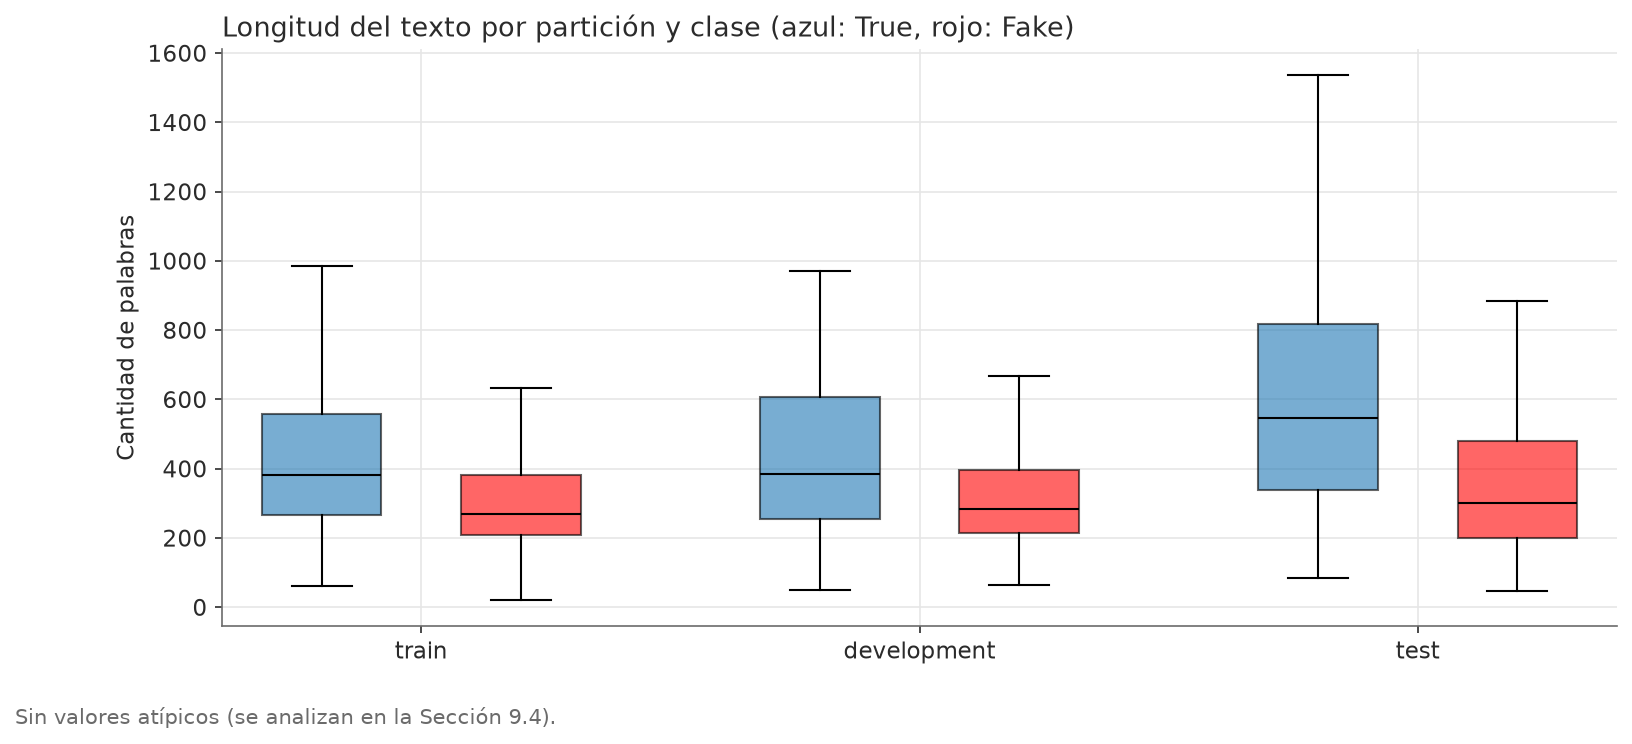

In [6]:
figura('9_1_longitud_por_clase')

**Tabla 2.3.** Casi duplicados entre particiones (coseno de TF-IDF ≥ 0.8) y dimensiones de calidad con algún problema.

In [7]:
duplicados = leer('eda_casi_duplicados.csv')
print(f'Pares de casi duplicados: {len(duplicados)}; de train hacia test: {int(((duplicados["particion_a"] == "train") & (duplicados["particion_b"] == "test")).sum())}')
calidad = leer('eda_calidad_dimensiones.csv')
calidad[['Dimensión', 'Resultado', '¿Problema?']]

Pares de casi duplicados: 11; de train hacia test: 4


,Dimensión,Resultado,¿Problema?
0,Exactitud (U2),1 pares casi duplicados con clase distinta,No evaluable
1,Completitud (U2),"72 titulares, 7 fuentes y 3 enlaces faltan en ...",Parcial
2,Consistencia (U2),"Columnas, clase y temas con formato distinto; ...",Sí
3,Validez (U2),7 de 8 reglas se cumplen; 43 enlaces no son URL,Parcial
4,Unicidad (U3),11 pares con coseno ≥ 0.8; 9 cruzan particiones,Sí
5,Accesibilidad (U2),Público en GitHub con licencia CC BY 4.0,No
6,Trazabilidad (U2),3 noticias sin enlace,Parcial
7,Relevancia (U2),3 temas del test no existen en train; 45.1 % d...,Parcial
8,Oportunidad (U2),2018 (train) frente a 2020–2021 (test),Parcial
9,Interpretabilidad (U2),Columnas documentadas; titulares faltantes exp...,No


**Qué se observa.**

* **La fuente es un atajo casi perfecto** (Tabla 2.1). Su V de Cramér con la clase es 0.996 en train, 1.000 en development y 0.956 en test: cada medio publica casi solo falsas o solo verdaderas. El tema, en cambio, casi no dice nada (0.099, 0.079 y 0.015). Por eso el proyecto **nunca usa la fuente** y valida agrupando por ella.
* **Las falsas son más cortas** (Tabla 2.2). Mediana de 269 contra 382 palabras en train (r = −0.371), y la brecha crece en el test (301 contra 545, r = −0.435). La longitud se vuelve el punto débil de todos los modelos: les cuesta detectar las falsas largas.
* **Hay 11 pares de casi duplicados, 4 de ellos de train hacia el test** (Tabla 2.3): fuga directa que se eliminó en la preparación.
* **Calidad:** hay problemas de consistencia y de unicidad, y la exactitud de las etiquetas no se puede evaluar (no hay acuerdo entre anotadores publicado).

**Los datos traen un atajo (el medio) que un modelo descuidado aprendería en lugar de la falsedad; todo el diseño del proyecto gira alrededor de evitarlo.**

<a id="fase-preparacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Preparación de los datos</span></div>

<a id="seccion-3"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 3: Preparación y folds agrupados por fuente</span></div>

> **Qué se hace:** resumimos lo que se limpió y cómo se partieron las 961 noticias para validar. Detalle: `preparacion_datos.ipynb` y `notas/preparacion_datos.md`.
>
> **Qué se espera ver:** pocas noticias eliminadas (solo duplicados) y 5 folds donde **cada fuente queda completa en un solo fold**, para que el modelo nunca se evalúe con medios que ya vio.

**Por qué agrupar por fuente.** Si las noticias de un mismo medio quedan repartidas entre entrenamiento y validación, el modelo puede acertar solo por reconocer el estilo del medio. Con folds aleatorios, la F1 sube entre 0.09 y 0.11 de forma artificial (Sección 4). Por eso **toda** la validación del proyecto usa `fold_grupo`.

**Tabla 3.1.** Bitácora de la preparación: qué se encontró, qué se hizo y a cuántas noticias afectó.

In [8]:
leer('preparacion_bitacora.csv')[['Hallazgo', 'Dimensión', 'Acción', 'Textos afectados']]

,Hallazgo,Dimensión,Acción,Textos afectados
0,Casi duplicados train ↔ test,Unicidad,Eliminar la copia de train,4
1,Casi duplicados train ↔ development y dentro d...,Unicidad,Eliminar la copia de development,6
2,Espacios repetidos y espacios duros,Consistencia,Normalizar espacios,338
3,Titular repetido al inicio del texto (v1.0),Consistencia,Quitar el prefijo,937
4,Números y URLs sin anonimizar (v2.0),Consistencia,Reemplazar por *NUMBER* y *URL*,499
5,Titular faltante solo en falsas (test),Completitud,Cadena vacía + bandera de análisis,72
6,Nombre o dominio del medio en el texto,Exactitud (atajo),Versión con los nombres de medio borrados,216
7,"Enlace ""Perma"" y fuente que delatan la clase",Validez,Excluir Link y Source de la entrada,1533
8,Textos largos atípicos,Exactitud,Conservar (legítimos),0


**Tabla 3.2.** Noticias por fold agrupado y clase.

In [9]:
folds = leer('folds.csv')
corpus_folds = folds[folds['particion'] != 'test']
tabla = pd.crosstab(corpus_folds['fold_grupo'], corpus_folds['Category'], margins = True, margins_name = 'total')
tabla['% falsas'] = (100 * tabla['Fake'] / tabla['total']).round(1)
print(f'Fuentes distintas: {corpus_folds["fuente"].nunique()}; fuentes que aparecen en más de un fold: {int((corpus_folds.groupby("fuente")["fold_grupo"].nunique() > 1).sum())}')
tabla

Fuentes distintas: 148; fuentes que aparecen en más de un fold: 0


Category,Fake,True,total,% falsas
fold_grupo,,,,
0,134,97,231,58.0
1,93,97,190,48.9
2,83,98,181,45.9
3,82,98,180,45.6
4,82,97,179,45.8
total,474,487,961,49.3


**Qué se observa.**

* **Se eliminó poco y con motivo** (Tabla 3.1): 4 copias de noticias del test y 6 duplicados dentro de development. El resto son normalizaciones (espacios, marcas de números y URLs), y se borraron los nombres de medio del texto en 216 noticias. `Link` y `Source` quedaron fuera de la entrada.
* **Folds agrupados por fuente** (Tabla 3.2): 148 fuentes y ninguna aparece en más de un fold. Los folds tienen 231, 190, 181, 180 y 179 noticias. El fold 0 tiene más falsas (58.0 %) que los demás (45.6 % a 48.9 %), por cómo se reparten las fuentes grandes.

**La validación del proyecto mide lo que importa en la práctica: qué tan bien funciona el modelo con medios que nunca vio.**

<a id="fase-modelado"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Modelado</span></div>

<a id="seccion-4"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 4: Modelos lineales y baselines</span></div>

> **Qué se hace:** mostramos los baselines, el modelo elegido y el diagnóstico que justifica agrupar por fuente. Detalle: `modelos_lineales.ipynb` (1,094 filas de CV) y `notas/modelado_lineales.md`.
>
> **Qué se espera ver:** que la LR sobre TF-IDF de palabras y caracteres supere a las réplicas de los baselines oficiales, y que los folds aleatorios inflen la F1.

**Tabla 4.1.** Baselines y modelo elegido (F1 de fake en CV agrupada, media y sd de 5 folds).

In [10]:
cv_lineales = leer('cv_lineales.csv')
agrupado = cv_lineales[cv_lineales['esquema'] == 'fold_grupo']
filas = []
for nombre in ['Clase mayoritaria', 'Aleatoria estratificada', 'Réplica 3-gramas de caracteres + SVM', 'Réplica BoW + SVM']:
    valores = agrupado[(agrupado['etapa'] == 'baselines') & (agrupado['modelo'] == nombre)]['F1_fake']
    filas.append({'sistema': nombre, 'F1 fake media': valores.mean(), 'sd': valores.std()})
elegida = agrupado[(agrupado['modelo'] == 'LR') & (agrupado['representación'] == 'palabras (1,2) + caracteres (2,5) | solo texto | sin medio')
                   & (agrupado['hiperparámetros'] == '{"valor": 1.0, "min_df": 20, "minusculas": true, "k_chi2": null}')]['F1_fake']
filas.append({'sistema': 'LR, palabras (1,2) + caracteres (2,5), solo texto, min_df 20, C = 1 (elegida)', 'F1 fake media': elegida.mean(), 'sd': elegida.std()})
pd.DataFrame(filas).round(4)

,sistema,F1 fake media,sd
0,Clase mayoritaria,0.3766,0.3438
1,Aleatoria estratificada,0.4948,0.0189
2,Réplica 3-gramas de caracteres + SVM,0.6791,0.0697
3,Réplica BoW + SVM,0.7072,0.0513
4,"LR, palabras (1,2) + caracteres (2,5), solo te...",0.7298,0.0951


**Tabla 4.2.** Diagnóstico: la misma configuración con folds agrupados por fuente y con folds aleatorios.

In [11]:
diagnostico = cv_lineales[cv_lineales['etapa'] == '4 diagnóstico folds']
tabla = diagnostico.groupby(['modelo', 'representación', 'esquema'])['F1_fake'].mean().unstack()
tabla['inflación por folds aleatorios'] = tabla['fold_aleatorio'] - tabla['fold_grupo']
tabla.round(3)

esquema                                                    fold_aleatorio  \
modelo representación                                                       
CNB    palabras (1,1) | solo texto | con medio                      0.789   
       palabras (1,1) | solo texto | sin medio                      0.790   
LR     palabras (1,2) + caracteres (2,5) | solo texto ...           0.842   
       palabras (1,2) + caracteres (2,5) | solo texto ...           0.838   
SVM    palabras (1,2) + caracteres (2,5) | solo texto ...           0.829   
       palabras (1,2) + caracteres (2,5) | solo texto ...           0.828   

esquema                                                    fold_grupo  \
modelo representación                                                   
CNB    palabras (1,1) | solo texto | con medio                  0.691   
       palabras (1,1) | solo texto | sin medio                  0.690   
LR     palabras (1,2) + caracteres (2,5) | solo texto ...       0.730   
       palabras (1,2) + caracteres (2,5) | solo texto ...       0.731   
SVM    palabras (1,2) + caracteres (2,5) | solo texto ...       0.736   
       palabras (1,2) + caracteres (2,5) | solo texto ...       0.733   

esquema                                                    inflación por folds aleatorios  
modelo representación                                                                      
CNB    palabras (1,1) | solo texto | con medio                                      0.098  
       palabras (1,1) | solo texto | sin medio                                      0.101  
LR     palabras (1,2) + caracteres (2,5) | solo texto ...                           0.112  
       palabras (1,2) + caracteres (2,5) | solo texto ...                           0.107  
SVM    palabras (1,2) + caracteres (2,5) | solo texto ...                           0.092  
       palabras (1,2) + caracteres (2,5) | solo texto ...                           0.095

**Figura 4.1.** F1 de fake por representación y estructura del texto (de `modelos_lineales.ipynb`).

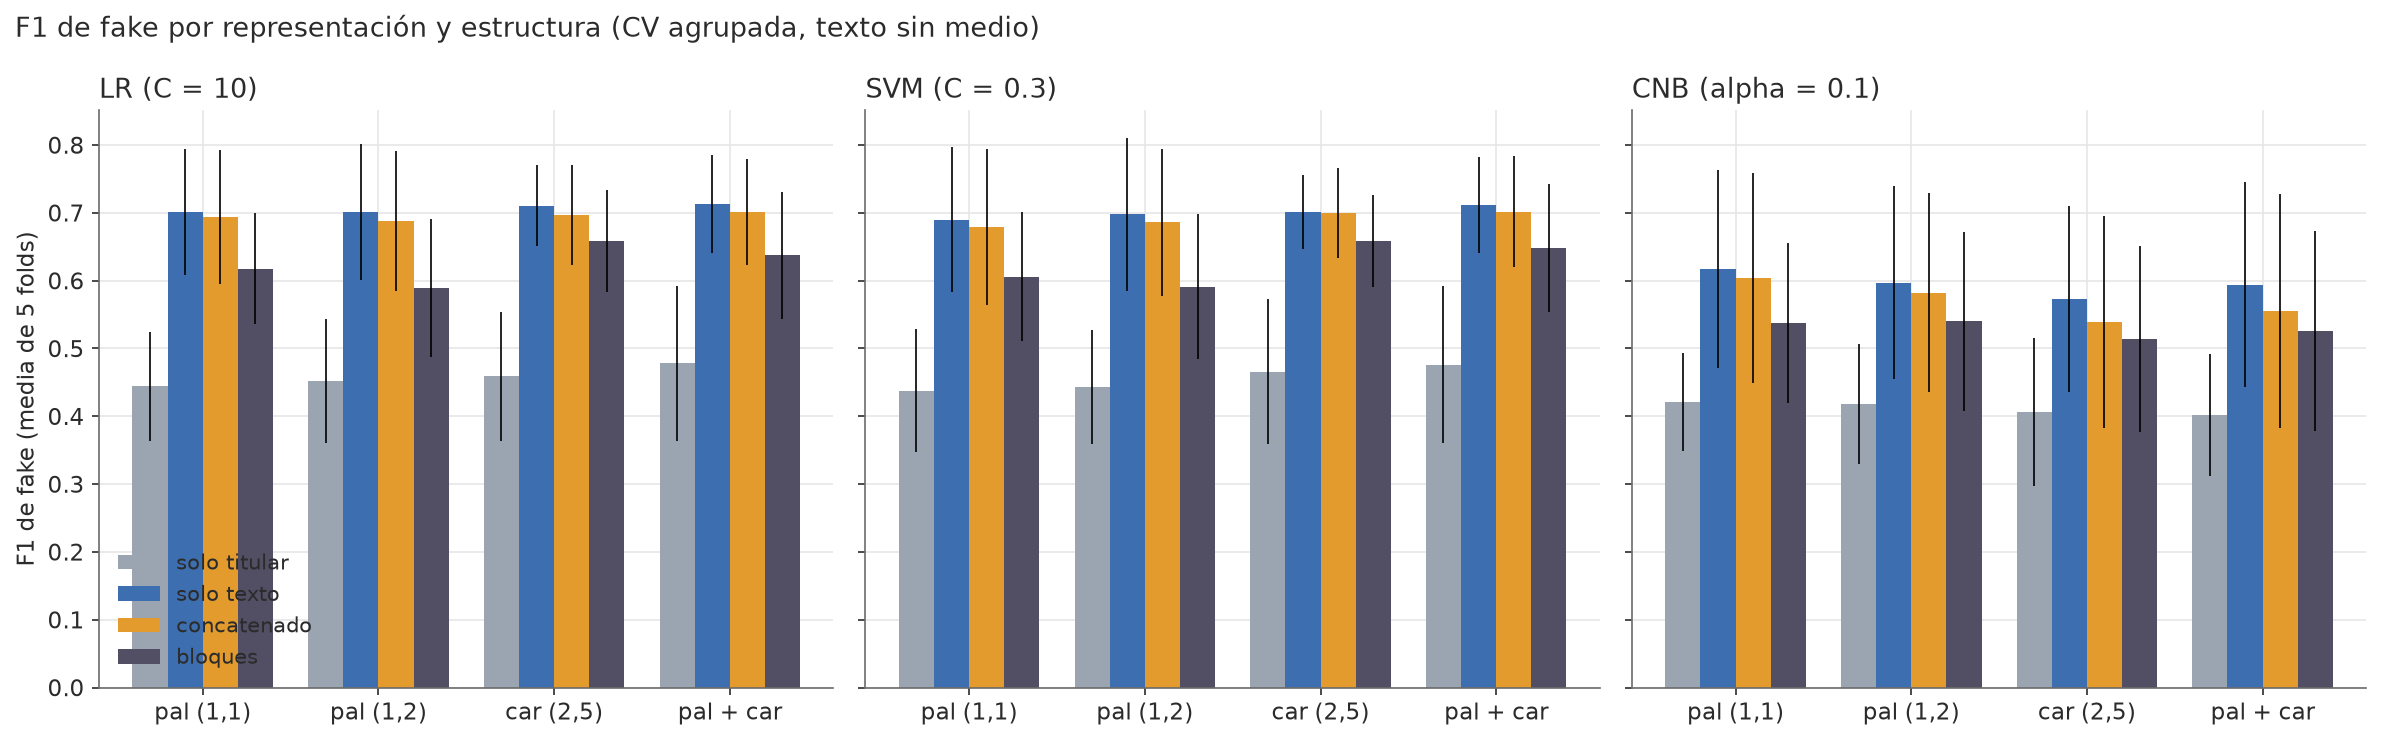

In [12]:
figura('3_1_representacion_estructura')

**Qué se observa.**

* **El modelo elegido supera a las réplicas de los baselines en CV** (Tabla 4.1): 0.7298 ± 0.0951, contra 0.7072 de la réplica de BoW + SVM y 0.6791 de la de 3-gramas. La ventaja sobre la réplica de BoW es menor que su sd, así que no está demostrada. Los baselines triviales quedan en 0.3766 (clase mayoritaria) y 0.4948 (aleatorio).
* **Los folds aleatorios inflan entre 0.092 y 0.112** (Tabla 4.2): la LR pasa de 0.730 a 0.842. Esa diferencia es lo que el modelo "aprende" reconociendo el estilo de medios ya vistos, y es la razón para agrupar por fuente.

**La LR sobre palabras y caracteres del texto es el sistema principal: el mejor en CV agrupada, simple y fácil de interpretar.**

<a id="seccion-5"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 5: Árboles sobre rasgos de estilo</span></div>

> **Qué se hace:** resumimos el Random Forest sobre 10 rasgos de estilo (longitud, mayúsculas, cifras, puntuación…). Detalle: `modelo_arboles.ipynb` y `notas/modelo_arboles.md`.
>
> **Qué se espera ver:** que el estilo solo quede debajo del texto, pero se equivoque en otras noticias.

**Tabla 5.1.** Árboles y LR sobre los mismos 10 rasgos, con folds agrupados y aleatorios.

In [13]:
cv_arboles = leer('cv_arboles.csv')
seleccion_arboles = leer('seleccion_arboles.json')
tabla = cv_arboles[cv_arboles['etapa'] == 'diagnóstico folds'].groupby(['hiperparámetros', 'esquema'])['F1_fake'].mean().unstack().round(3)
print(f'Random Forest elegido {seleccion_arboles["elegida"]["parametros"]}: {seleccion_arboles["cv_elegida"]["F1_fake_mean"]:.4f} ± {seleccion_arboles["cv_elegida"]["F1_fake_std"]:.4f}')
tabla

Random Forest elegido {'max_depth': 3, 'max_features': 'sqrt', 'min_samples_leaf': 20}: 0.6083 ± 0.1678


esquema,fold_aleatorio,fold_grupo
hiperparámetros,,
LR sobre rasgos,0.757,0.672
RF,0.768,0.626


**Figura 5.1.** Importancia de los rasgos de estilo por permutación (de `modelo_arboles.ipynb`).

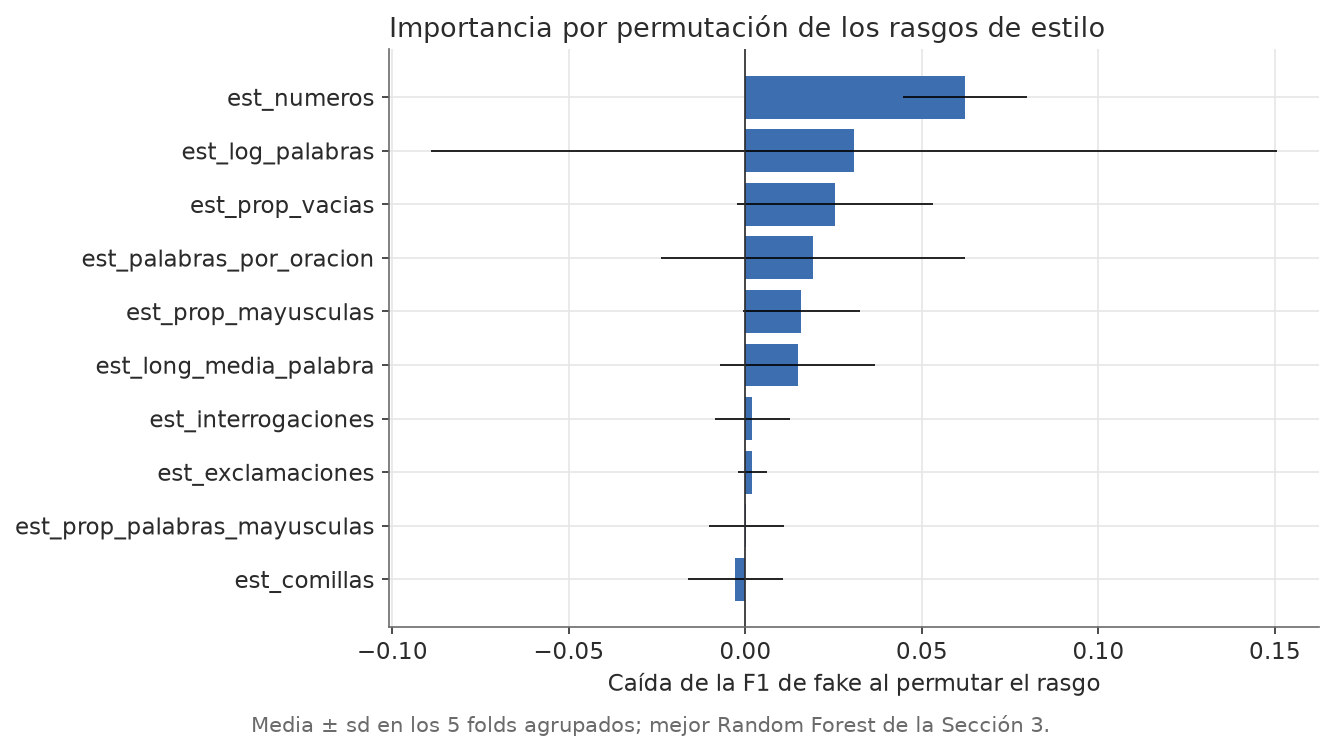

In [14]:
figura('4_1_importancia_rasgos')

**Qué se observa.**

* **El estilo solo queda muy por debajo del texto:** el Random Forest elegido saca 0.6083 ± 0.1678 y la LR sobre los mismos rasgos 0.672 (Tabla 5.1).
* **Con folds aleatorios, los rasgos de estilo también suben mucho** (el bosque, de 0.626 a 0.768): sirven sobre todo para reconocer medios.
* La no linealidad del bosque no ayuda frente a la LR sobre los mismos rasgos.

**El estilo por sí solo no basta; su valor está en equivocarse en otras noticias que el modelo de texto, algo que se aprovecha (sin éxito) en los ensambles.**

<a id="fase-evaluacion"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Metodología CRISP-DM: Evaluación</span></div>

<a id="seccion-6"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 6: El sistema principal en el test</span></div>

> **Qué se hace:** mostramos el resultado de la **única** evaluación en el test de los sistemas fijados en la fase de modelado. Detalle: `evaluacion.ipynb` y `notas/evaluacion.md`.
>
> **Qué se espera ver:** que el principal quede cerca de .72, con una caída respecto a la CV porque el test es de otra época y tiene temas nuevos.

**Tabla 6.1.** Sistemas fijados antes de abrir el test: métricas en el test con IC95 bootstrap y su F1 en CV.

In [15]:
test_final = leer('test_final.csv')
test_final[['sistema', 'F1_fake', 'IC95 F1_fake', 'F1_fake en CV', 'precision_fake', 'recall_fake', 'accuracy']]

,sistema,F1_fake,IC95 F1_fake,F1_fake en CV,precision_fake,recall_fake,accuracy
0,LR texto (principal),0.6764,"[0.629, 0.722]",0.730,0.8394,0.5664,0.7290
1,SVM texto (mejor media en CV),0.6751,"[0.625, 0.721]",0.733,0.8429,0.5629,0.7290
2,SVM texto + χ² (regla original),0.6112,"[0.554, 0.660]",0.702,0.7538,0.5140,0.6731
3,Réplica BoW + SVM,0.6600,"[0.608, 0.707]",0.707,0.7710,0.5769,0.7028
4,Réplica 3-gramas + SVM,0.6181,"[0.563, 0.665]",0.679,0.7072,0.5490,0.6608
5,Random Forest (estilo),0.5054,"[0.446, 0.560]",0.608,0.6610,0.4091,0.5997
6,Clase mayoritaria,0.0000,"[0.000, 0.000]",0.377,0.0000,0.0000,0.5000


**Figura 6.1.** F1 de fake en el test frente a los resultados oficiales, y matriz de confusión del principal (de `evaluacion.ipynb`).

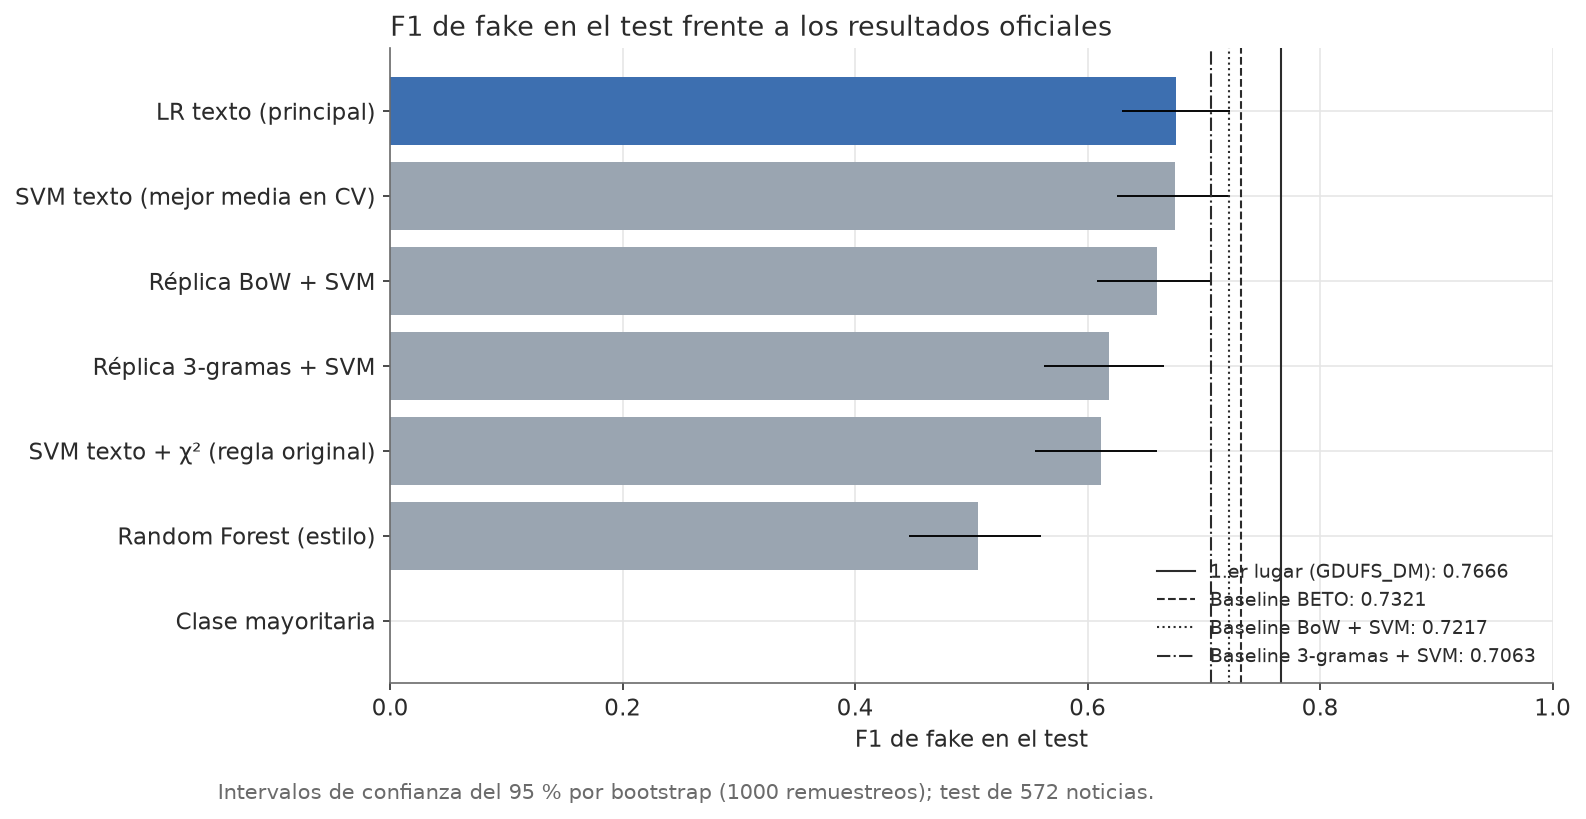

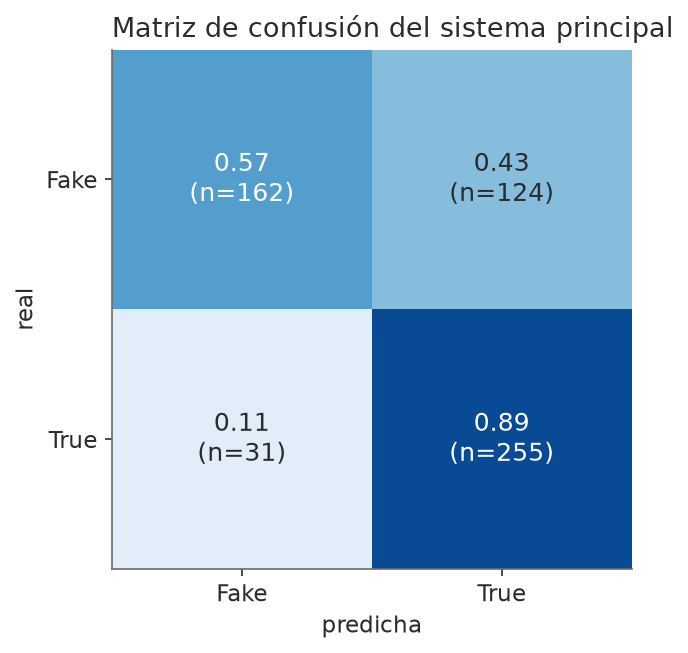

In [16]:
figura('3_1_f1_test_vs_oficiales')
figura('5_1_matriz_confusion', ancho = 420)

**Qué se observa.**

* **El principal saca 0.6764 en el test** (IC95 [0.629, 0.722]), contra 0.730 en CV. El baseline oficial (.7217) queda justo en la orilla de su intervalo: **no se cumplió la meta** en esta fase.
* **Su problema es la exhaustividad:** acierta mucho cuando marca una falsa (precisión 0.8394), pero solo detecta el 56.6 % de las falsas (0.5664).
* **Nuestra réplica de BoW también queda debajo de la oficial** (0.6600 contra .7217), así que una parte de la brecha viene del preprocesamiento oficial (lematización, sin números ni puntuación).
* El Random Forest de estilo cae a 0.5054.

**El principal es preciso pero tímido: deja pasar casi la mitad de las falsas, sobre todo las largas. Las mejoras de las Secciones 7 a 9 atacan justo eso.**

<a id="seccion-7"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 7: Mejoras como sistema aparte: umbral y primer ensamble</span></div>

> **Qué se hace:** resumimos las dos mejoras que se probaron después de ver la baja exhaustividad del principal: bajar el umbral de decisión y combinar modelos (XGBoost + Random Forest + LR). Detalle: `umbral.ipynb`, `ensamble_stacking.ipynb` y sus notas.
>
> **Qué se espera ver:** que el umbral recupere falsas (a costa de falsas alarmas) y que el ensamble con bases parecidas no ayude.

**Tabla 7.1.** Umbral de decisión: elegido con CV anidada (cada fold elige su umbral sin verse a sí mismo) y aplicado una vez al test.

In [17]:
umbral_anidado = leer('umbral_anidado.csv')
print(f'Umbrales elegidos por fold: {umbral_anidado["umbral elegido (interno)"].tolist()}; '
      f'F1 media con 0.5: {umbral_anidado["F1 fake con 0.5"].mean():.4f}; con umbral interno: {umbral_anidado["F1 fake con umbral interno"].mean():.4f}')
leer('umbral_test.csv')[['sistema', 'F1_fake', 'IC95 F1_fake', 'precision_fake', 'recall_fake', 'accuracy', 'predichas Fake']]

Umbrales elegidos por fold: [0.39, 0.36, 0.43, 0.38, 0.39]; F1 media con 0.5: 0.7298; con umbral interno: 0.7442


,sistema,F1_fake,IC95 F1_fake,precision_fake,recall_fake,accuracy,predichas Fake
0,"LR texto (principal, umbral 0.5)",0.6764,"[0.629, 0.722]",0.8394,0.5664,0.7290,193
1,"LR texto, umbral 0.34 (sistema aparte)",0.7346,"[0.696, 0.771]",0.6837,0.7937,0.7133,332


**Tabla 7.2.** Primer ensamble (sin transformers): F1 de fake en CV anidada y en el test.

In [18]:
stacking_cv = leer('stacking_cv.csv')
print(f'CV anidada: LR {stacking_cv["LR texto"].mean():.4f}; XGBoost {stacking_cv["XGBoost"].mean():.4f}; RF {stacking_cv["RF estilo"].mean():.4f}; '
      f'soft voting {stacking_cv["soft voting"].mean():.4f}; stacking {stacking_cv["stacking"].mean():.4f}')
leer('stacking_test.csv')[['sistema', 'F1_fake', 'IC95 F1_fake', 'F1_fake en CV']]

CV anidada: LR 0.7298; XGBoost 0.6773; RF 0.6083; soft voting 0.6985; stacking 0.6842


,sistema,F1_fake,IC95 F1_fake,F1_fake en CV
0,LR texto (principal),0.6764,"[0.629, 0.722]",0.730
1,"LR texto, umbral 0.34",0.7346,"[0.696, 0.771]",0.744
2,XGBoost,0.6424,"[0.592, 0.691]",0.677
3,RF estilo,0.5054,"[0.446, 0.560]",0.608
4,Soft voting (3 bases),0.6446,"[0.595, 0.693]",0.698
5,Stacking (meta-modelo LR),0.6960,"[0.652, 0.741]",0.684


**Qué se observa.**

* **Bajar el umbral funciona** (Tabla 7.1). La CV anidada elige umbrales de 0.36 a 0.43 y espera 0.7442. Con 0.34, el test sube a 0.7346 (IC95 [0.696, 0.771]). La exhaustividad pasa de 0.5664 a 0.7937, pero la precisión baja a 0.6837 y la exactitud de 0.7290 a 0.7133: detecta más falsas a cambio de más falsas alarmas.
* **El primer ensamble no ayuda** (Tabla 7.2). En CV anidada, el stacking de LR + XGBoost + Random Forest saca 0.6842, por debajo de la LR sola (0.7298). En el test da 0.6960, y se explica casi todo por el cambio de umbral que hace su meta-modelo. Las bases leen la noticia igual que la LR y comparten su punto ciego.

**Mover el umbral es la mejora más barata y efectiva para la F1 de fake; combinar modelos parecidos no sirve.**

<a id="seccion-8"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 8: Transformers y ensambles con BETO</span></div>

> **Qué se hace:** resumimos los siete sistemas con BETO, fijados antes de ver sus resultados. Detalle: `beto_resultados.ipynb`, `ensamble_beto.ipynb` (Secciones 1 a 9) y `notas/ensamble_beto.md`.
>
> **Qué se espera ver:** que BETO se equivoque en noticias distintas que la LR y que el stacking por fin complemente.

**Tabla 8.1.** Los siete sistemas con BETO y las bases (CV con esquema B para los meta-modelos; test con IC95).

In [19]:
resumen_beto = leer('beto_resumen_sistemas.csv')
fijados = resumen_beto[resumen_beto['exploratorio'] == 'no']
fijados[['sistema', 'bloque', 'CV F1_fake', 'CV sd F1_fake', 'test F1_fake', 'test IC95 F1_fake', 'test recall_fake']].round(3)

,sistema,bloque,CV F1_fake,CV sd F1_fake,test F1_fake,test IC95 F1_fake,test recall_fake
0,LR texto (principal),base,0.730,0.095,0.676,"[0.629, 0.722]",0.566
1,XGBoost,base,0.685,0.066,0.637,"[0.586, 0.686]",0.552
2,RF estilo,base,0.608,0.168,0.505,"[0.446, 0.560]",0.409
3,1. BETO solo,base / sistema 1,0.656,0.196,0.693,"[0.643, 0.736]",0.612
4,2. Soft voting LR + BETO,sistema fijo,0.682,0.137,0.708,"[0.660, 0.752]",0.619
5,3. Stacking LR (LR + BETO),sistema fijo,0.746,0.055,0.736,"[0.690, 0.778]",0.696
6,4. Stacking LR (4 bases),sistema fijo,0.730,0.070,0.738,"[0.693, 0.778]",0.689
7,5. Stacking MLP (4 bases),sistema fijo,0.734,0.080,0.745,"[0.700, 0.783]",0.720
8,6. Stacking LR (4 bases + longitud),sistema fijo,0.708,0.128,0.757,"[0.712, 0.796]",0.706
9,7. Stacking MLP (4 bases + longitud),sistema fijo,0.723,0.091,0.736,"[0.692, 0.776]",0.689


**Figura 8.1.** F1 de fake en el test de los sistemas con BETO (de `ensamble_beto.ipynb`).

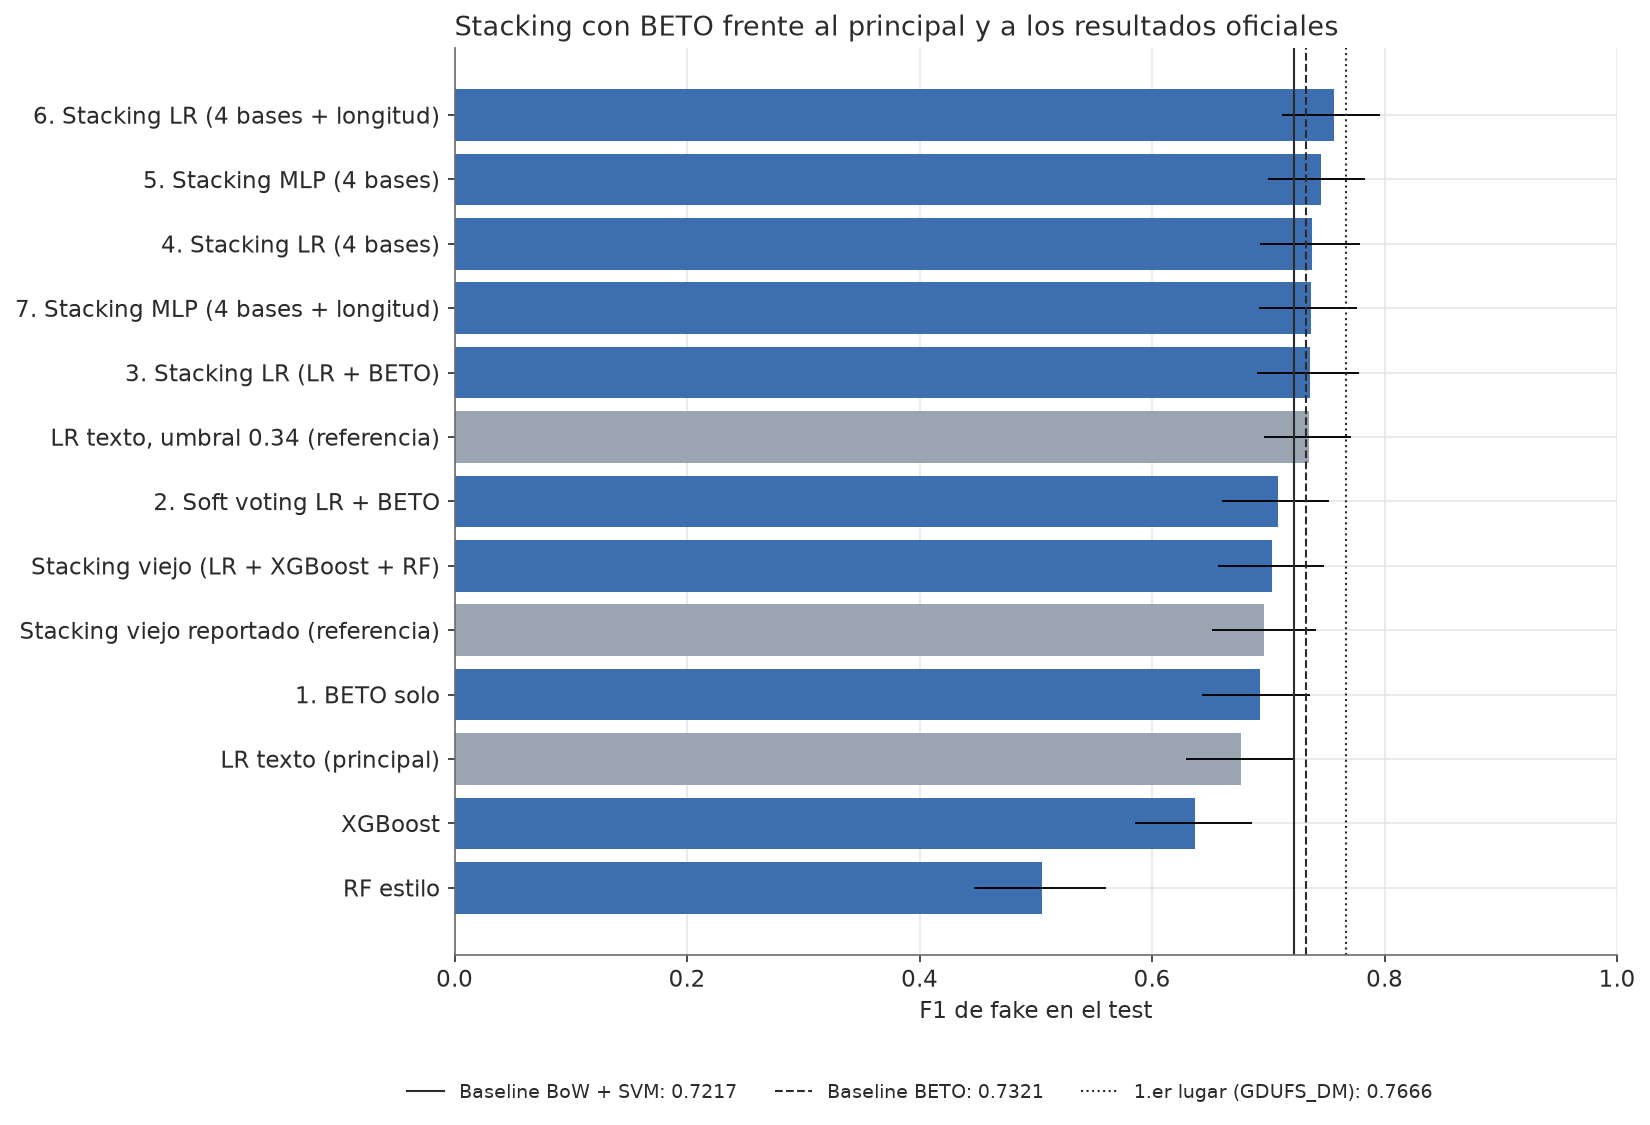

In [20]:
figura('7_2_beto_f1_test')

**Qué se observa.**

* **BETO solo no le gana a la LR en CV** (0.656), pero en el test sube a 0.693, y se equivoca en noticias distintas: falla en la sátira de *El Ruinaversal*, donde la LR acierta, y detecta más falsas largas.
* **El sistema 3 (stacking LR + BETO) es el mejor de los fijados en CV** (0.746) y en el test saca 0.736 (IC95 [0.690, 0.778]).
* **Los cinco stackings con BETO superan al principal en el test**, de 0.736 a 0.757. El 6 es el más alto en el test (0.757), pero fue el peor stacking en CV (0.708): elegirlo sería decidir con el test.
* La red neuronal como meta-modelo no le gana a la LR (sistema 5: 0.734 en CV).

**Con una base que lee distinto, el ensamble por fin complementa a la LR; en el test empata con el umbral 0.34.**

<a id="seccion-9"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 9: Exploraciones y prueba de contaminación</span></div>

> **Qué se hace:** resumimos lo que se probó **después** de ver los resultados del test: FT-Transformer, boostings, SVM, kNN y Naive Bayes, BERTIN y XLM-RoBERTa, y meta-modelos con pesos no negativos y umbral anidado. También la prueba de si BERTIN ya conocía los textos. Detalle: `ensamble_beto.ipynb` (Secciones 10 a 14).
>
> **Qué se espera ver:** que lo exploratorio quede etiquetado como tal y que su ventaja en CV no se sostenga del todo en el test.

**Tabla 9.1.** Sistemas y bases exploratorios (no son candidatos a sistema final).

In [21]:
exploratorios = resumen_beto[resumen_beto['exploratorio'] == 'sí']
exploratorios[['sistema', 'CV F1_fake', 'test F1_fake', 'test IC95 F1_fake']].round(3)

,sistema,CV F1_fake,test F1_fake,test IC95 F1_fake
13,FT-Transformer (exploratorio),0.714,0.755,"[0.713, 0.795]"
14,Stacking LR + BETO + 3 boostings (exploratorio...,0.733,0.734,"[0.687, 0.774]"
15,E1. Sistema 3 + umbral anidado (exploratorio),0.747,0.744,"[0.702, 0.781]"
16,E2. Stacking LR (LR + 3 transformers) (explora...,0.798,0.740,"[0.696, 0.779]"
17,"E3. Stacking no negativo, todas las bases (exp...",0.812,0.750,"[0.708, 0.789]"
18,E4. Stacking no negativo + umbral anidado (exp...,0.813,0.755,"[0.715, 0.794]"
19,SVM-RBF (embeddings) (base exploratoria),0.672,0.675,"[0.628, 0.723]"
20,kNN (embeddings) (base exploratoria),0.559,0.486,"[0.423, 0.539]"
21,Naive Bayes (palabras) (base exploratoria),0.673,0.617,"[0.562, 0.664]"
22,BERTIN (base exploratoria),0.810,0.726,"[0.684, 0.767]"


**Tabla 9.2.** Prueba de contaminación: acierto (%) al adivinar el 15 % de palabras tapadas con cada transformer preentrenado, por grupo de noticias, y búsqueda de las noticias del corpus en el corpus de preentrenamiento de BERTIN.

In [22]:
contaminacion = leer('contaminacion_mlm.csv')
fuentes = corpus_folds.set_index('id_unico')['fuente']
clase = corpus_folds.set_index('id_unico')['Category']
grupo = []
for id_unico in contaminacion['id_unico']:
    if id_unico not in fuentes.index:
        grupo.append('test (2021)')
    elif fuentes[id_unico] == 'el ruinaversal':
        grupo.append('falsas de El Ruinaversal')
    elif clase[id_unico] == 'Fake':
        grupo.append('otras falsas del corpus')
    else:
        grupo.append('verdaderas del corpus')
contaminacion['grupo'] = grupo
display(contaminacion.pivot_table(index = 'grupo', columns = 'modelo', values = 'acierto_top1', aggfunc = 'mean').mul(100).round(1))
noticias = leer('contaminacion_busqueda_noticias.csv')
control = leer('contaminacion_busqueda_control.csv')
print(f'Noticias del corpus encontradas con su URL exacta en mC4: {int((noticias["en mC4 (BERTIN)"] == "encontrada").sum())} de {len(noticias)}; '
      f'control positivo encontrado: {int((control["resultado del método noticia por noticia"] == "encontrada").sum())} de {len(control)}')

modelo,BERTIN,BETO,XLM-RoBERTa
grupo,,,
falsas de El Ruinaversal,68.6,43.8,66.4
otras falsas del corpus,68.6,43.4,66.1
test (2021),69.7,43.7,68.1
verdaderas del corpus,73.4,44.1,70.0


Noticias del corpus encontradas con su URL exacta en mC4: 0 de 367; control positivo encontrado: 4 de 5


**Figura 9.1.** Curva del umbral del sistema 3 y prueba de contaminación (de `ensamble_beto.ipynb`).

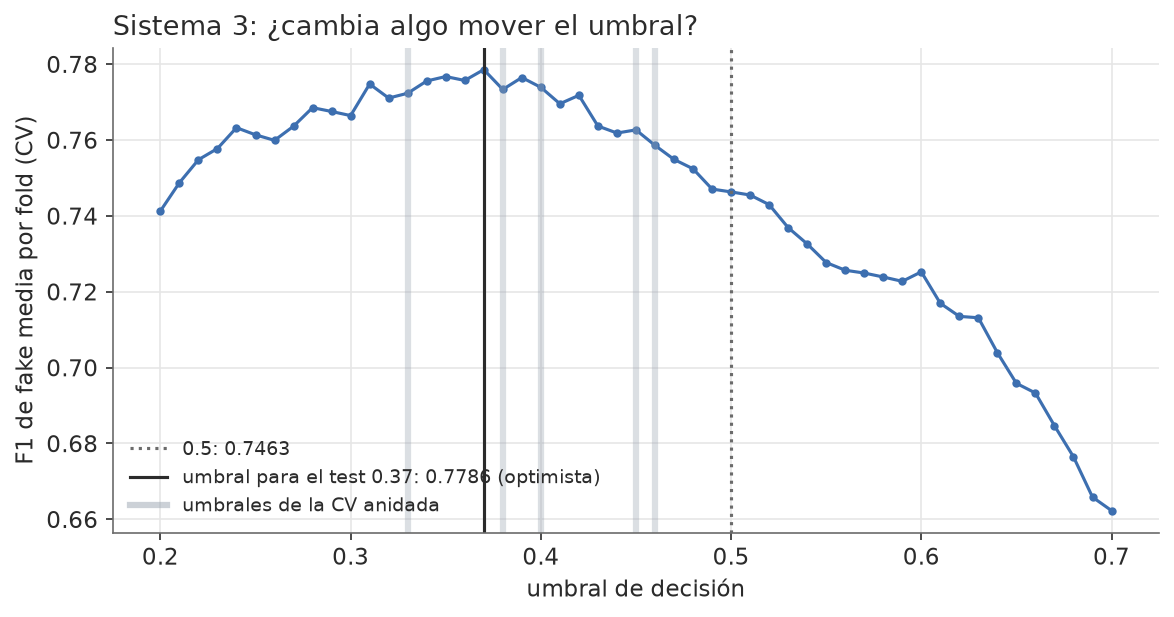

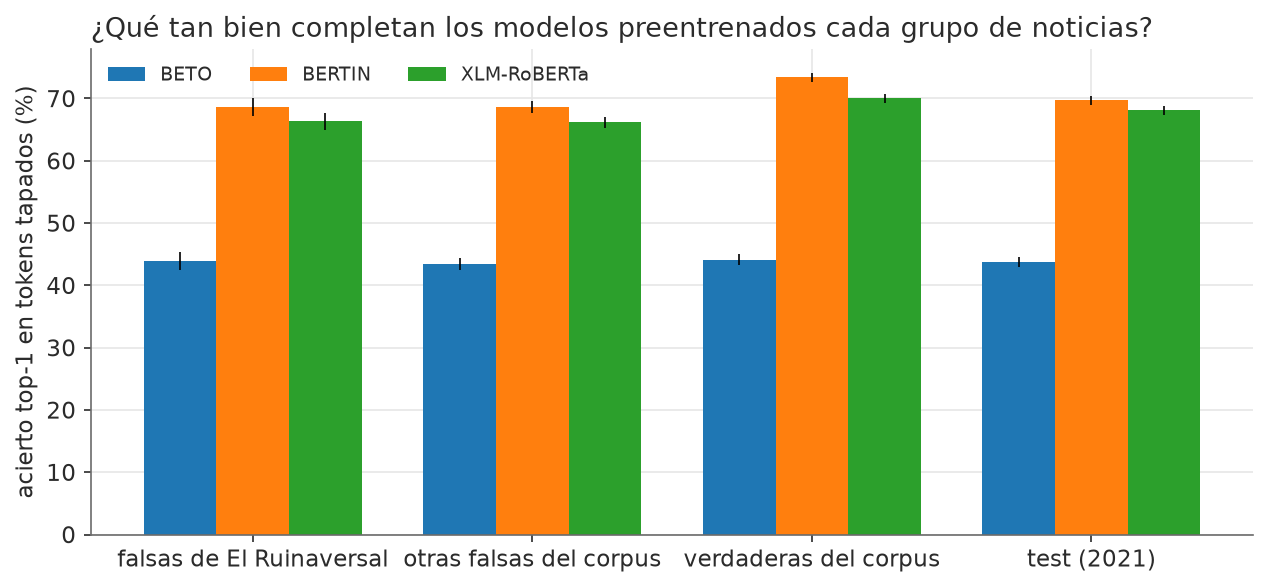

In [23]:
figura('13_1_beto_umbral_sistema3')
figura('12_1_beto_contaminacion')

**Qué se observa.**

* **Lo exploratorio se ve muy bien en CV y menos en el test** (Tabla 9.1):
  * BERTIN pasa de 0.810 a 0.726;
  * los meta-modelos que lo incluyen pierden alrededor de 0.06 (E4: de 0.813 a 0.755; E3: de 0.812 a 0.750; E2: de 0.798 a 0.740);
  * el FT-Transformer sube de 0.714 a 0.755 y el kNN se queda en 0.486.
* **Contaminación** (Tabla 9.2):
  * BERTIN no completa mejor las palabras tapadas de la sátira (68.6 %) que las del test, que no pudo haber visto (69.7 %); sí completa mejor las verdaderas del corpus (73.4 %).
  * Ninguna de las 367 noticias del corpus que se buscaron aparece con su URL exacta en su corpus de preentrenamiento. El método sí encontró 4 de las 5 páginas del control positivo (la quinta no tiene palabras en su URL que buscar).
* **Interpretación:** BERTIN conocía el estilo de los sitios del corpus, no sus noticias. Esa familiaridad infla su CV.

**Las exploraciones confirman que se puede llegar a ≈ 0.75 en el test, pero ninguna se distingue del sistema 3 ni del umbral 0.34, y su CV es optimista.**

<a id="seccion-10"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 10: Los tres finalistas: sistema 3, E3 y E4</span></div>

> **Qué se hace:** resumimos el análisis a fondo de los tres finalistas: métricas, matrices de confusión, entrenamiento e interpretación (SHAP por base y LIME por palabra). Detalle completo: `finalistas.ipynb` y `finalistas_lime.py`.
>
> **Qué se espera ver:** tres sistemas en ≈ 0.74–0.76 en el test, sin diferencias significativas entre ellos, y explicaciones que muestren qué base y qué palabras deciden.

| Finalista | Qué es | Por qué es finalista | Advertencia |
|:--|:--|:--|:--|
| **3. Stacking LR + BETO** | Regresión logística sobre las probabilidades de la LR de texto y de BETO | El elegido por el protocolo: el mejor en CV de los sistemas fijados antes de su test | — |
| **E3. Pesos no negativos** | Regresión logística con pesos ≥ 0 sobre 12 bases (incluidos BETO y BERTIN) | El mejor en CV del proyecto (con E4) | Diseñado después de ver el test; su CV se apoya en BERTIN, cuya CV es optimista |
| **E4. E3 + umbral anidado** | El modelo de E3 con el corte elegido en CV | El más alto de los exploratorios en el test | Igual que E3 |

**Tabla 10.1.** Métricas de los finalistas en CV (media ± sd de 5 folds) y en el test (con IC95 bootstrap).

In [24]:
metricas_cv_f = leer('finalistas_metricas_cv.csv')
media = metricas_cv_f.drop(columns = 'fold').groupby('finalista', sort = False).mean()
sd = metricas_cv_f.drop(columns = 'fold').groupby('finalista', sort = False).std()
display((media.round(4).astype(str) + ' ± ' + sd.round(4).astype(str)).add_prefix('CV '))
leer('finalistas_metricas_test.csv').set_index('sistema')

,CV F1_fake,CV F1_true,CV F1_macro,CV accuracy,CV precision_fake,CV recall_fake
finalista,,,,,,
3. Stacking LR + BETO,0.7463 ± 0.0554,0.7877 ± 0.0233,0.767 ± 0.032,0.7712 ± 0.0294,0.8049 ± 0.0679,0.7052 ± 0.0979
E3. Pesos no negativos,0.8116 ± 0.057,0.8262 ± 0.0642,0.8189 ± 0.051,0.8233 ± 0.0479,0.8376 ± 0.0482,0.7926 ± 0.0953
E4. E3 + umbral anidado,0.813 ± 0.0596,0.8198 ± 0.0682,0.8164 ± 0.0541,0.8208 ± 0.051,0.8201 ± 0.0542,0.8098 ± 0.089


,F1_fake,F1_true,F1_macro,accuracy,precision_fake,recall_fake,IC95 F1_fake,predichas Fake
sistema,,,,,,,,
3. Stacking LR + BETO,0.7357,0.7629,0.7493,0.7500,0.7804,0.6958,"[0.690, 0.778]",255
E3. Pesos no negativos,0.7496,0.7361,0.7428,0.7430,0.7309,0.7692,"[0.708, 0.789]",301
E4. E3 + umbral anidado,0.7550,0.7259,0.7404,0.7413,0.7170,0.7972,"[0.715, 0.794]",318
LR texto (principal),0.6764,0.7669,0.7217,0.7290,0.8394,0.5664,"[0.629, 0.722]",193
"LR texto, umbral 0.34",0.7346,0.6882,0.7114,0.7133,0.6837,0.7937,"[0.696, 0.771]",332


**Tabla 10.2.** Comparaciones pareadas en el test entre los finalistas y contra el principal y el umbral 0.34.

In [25]:
leer('finalistas_comparaciones.csv')

,sistema,referencia,diferencia F1 fake,IC95 pareado,remuestreos en que gana,McNemar (solo a / solo b),p McNemar
0,E3. Pesos no negativos,3. Stacking LR + BETO,0.014,"[-0.025, +0.050]",774 de 1000,44 / 48,0.755
1,E4. E3 + umbral anidado,3. Stacking LR + BETO,0.019,"[-0.019, +0.056]",855 de 1000,48 / 53,0.691
2,E4. E3 + umbral anidado,E3. Pesos no negativos,0.005,"[-0.007, +0.020]",798 de 1000,8 / 9,1.000
3,3. Stacking LR + BETO,LR texto (principal),0.059,"[+0.020, +0.100]",998 de 1000,53 / 41,0.256
4,3. Stacking LR + BETO,"LR texto, umbral 0.34",0.001,"[-0.038, +0.038]",529 de 1000,72 / 51,0.071
5,E3. Pesos no negativos,LR texto (principal),0.073,"[+0.024, +0.122]",997 de 1000,73 / 65,0.551
6,E3. Pesos no negativos,"LR texto, umbral 0.34",0.015,"[-0.020, +0.050]",803 de 1000,67 / 50,0.139
7,E4. E3 + umbral anidado,LR texto (principal),0.079,"[+0.029, +0.125]",998 de 1000,80 / 73,0.628
8,E4. E3 + umbral anidado,"LR texto, umbral 0.34",0.020,"[-0.014, +0.053]",877 de 1000,66 / 50,0.163


**Figura 10.1.** Matrices de confusión de los finalistas: CV arriba, test abajo (de `finalistas.ipynb`).

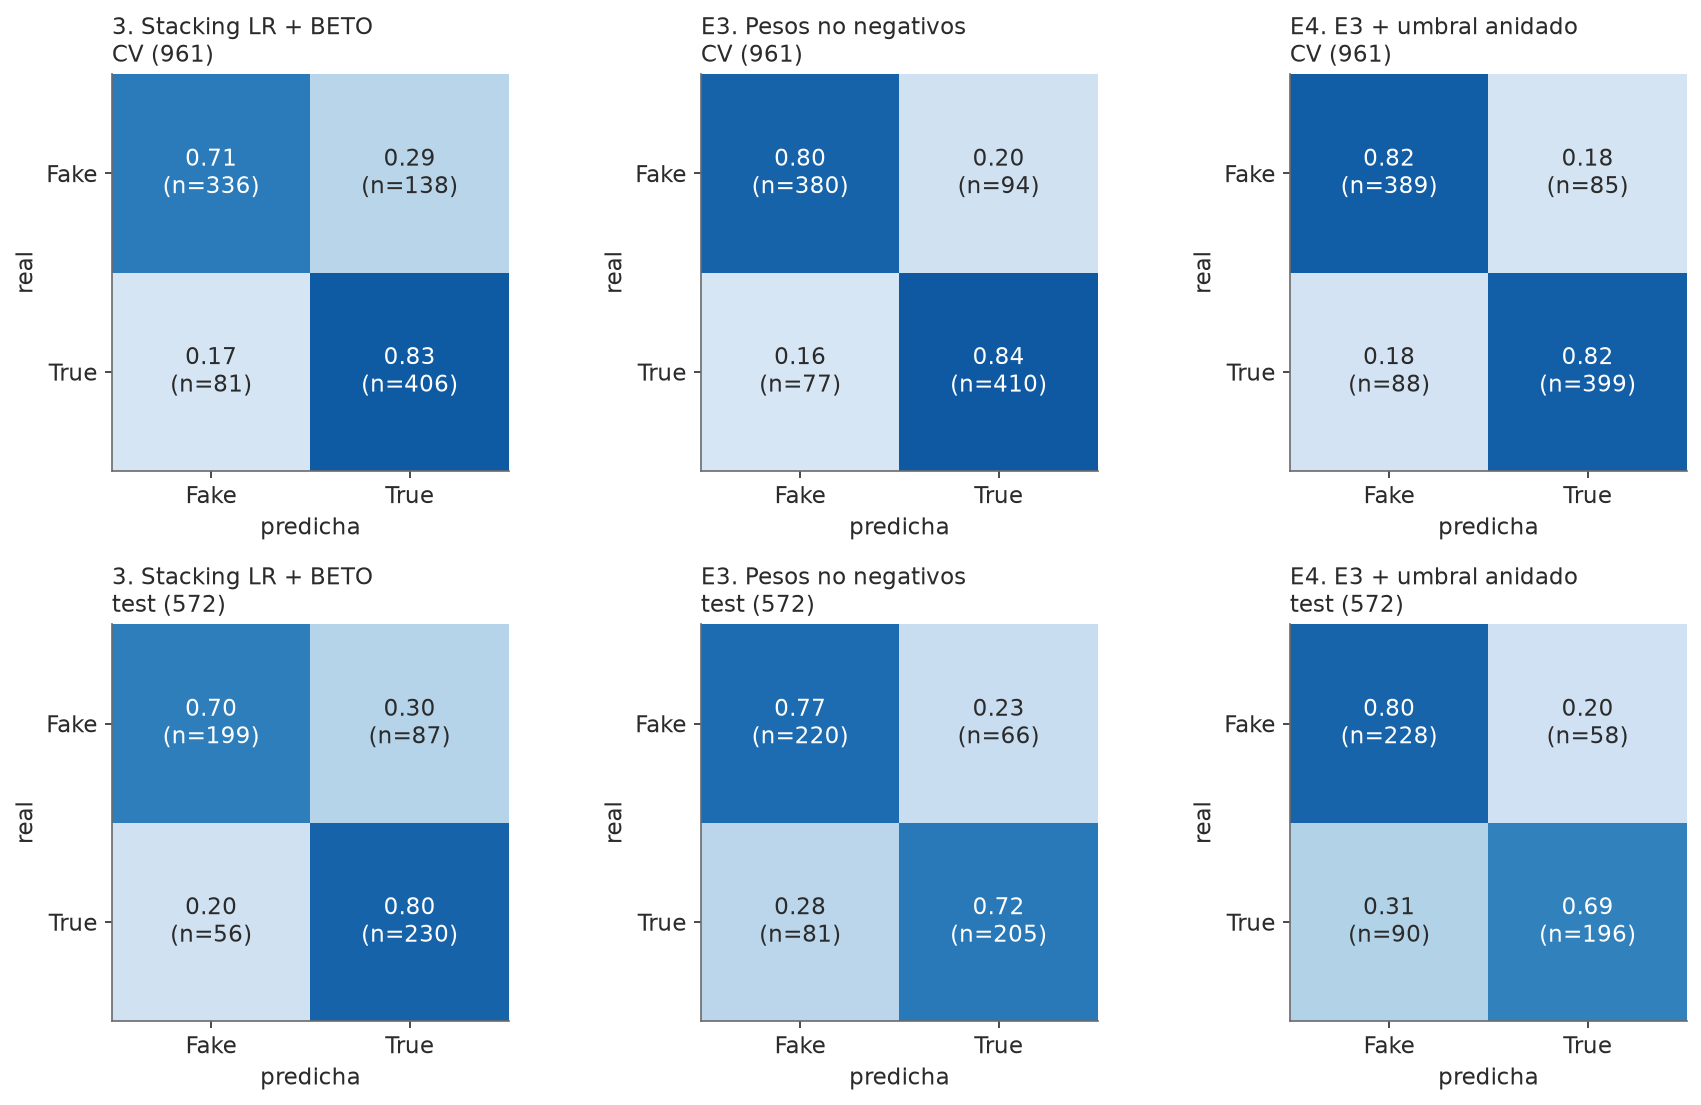

In [26]:
figura('3_1_finalistas_matrices', ancho = 860)

**Figura 10.2.** Entrenamiento: pérdida por época de BETO y BERTIN, pérdida del optimizador de los meta-modelos y curva del umbral de E4 (de `finalistas.ipynb`).

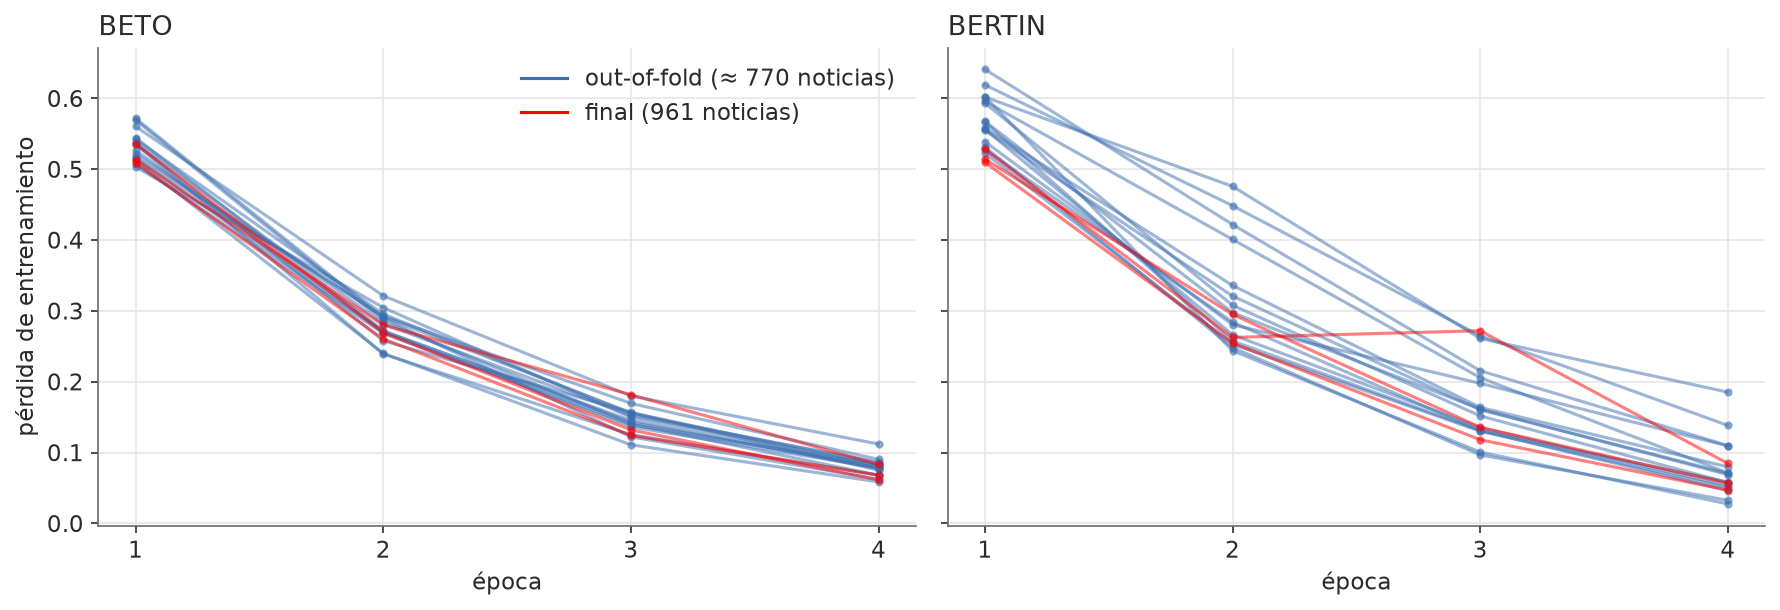

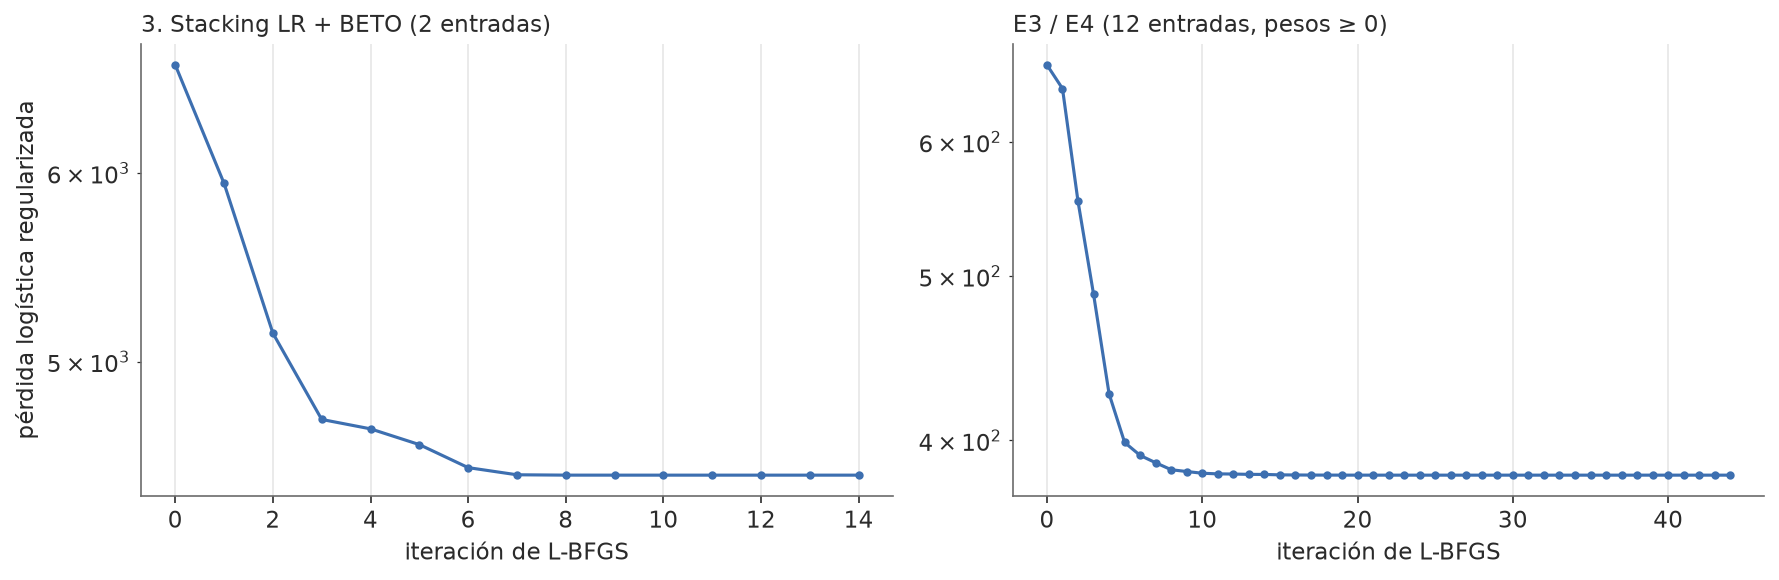

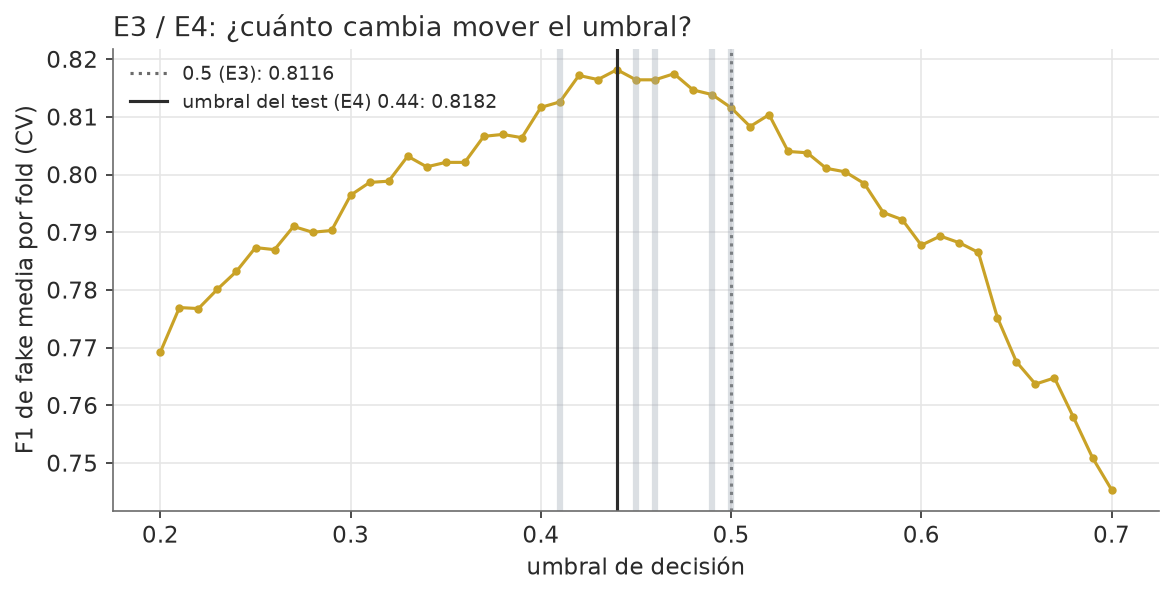

In [27]:
figura('4_1_finalistas_perdida_transformers', ancho = 860)
figura('5_1_finalistas_perdida_meta', ancho = 860)
figura('6_1_finalistas_umbral_e4')

**Tabla 10.3.** Qué aporta cada base: importancia global (media |SHAP| exacto en el test, escala logit) en los dos meta-modelos.

In [28]:
importancias_f = leer('finalistas_shap_bases.csv')
importancias_f[importancias_f['media |SHAP|'] > 0].round(3)

,meta-modelo,base,media |SHAP|,participación (%)
0,3. Stacking LR + BETO,BETO,0.990,53.405
1,3. Stacking LR + BETO,LR texto,0.864,46.595
2,E3 / E4,BERTIN,1.114,49.966
3,E3 / E4,XGBoost,0.279,12.528
4,E3 / E4,BETO,0.273,12.252
5,E3 / E4,HistGradientBoosting (caracteres),0.253,11.338
6,E3 / E4,LR texto,0.180,8.087
7,E3 / E4,SVM-RBF (embeddings),0.130,5.814
8,E3 / E4,Naive Bayes (palabras),0.000,0.014


**Figura 10.3.** SHAP por base y LIME por palabra en las seis noticias explicadas (de `finalistas.ipynb`).

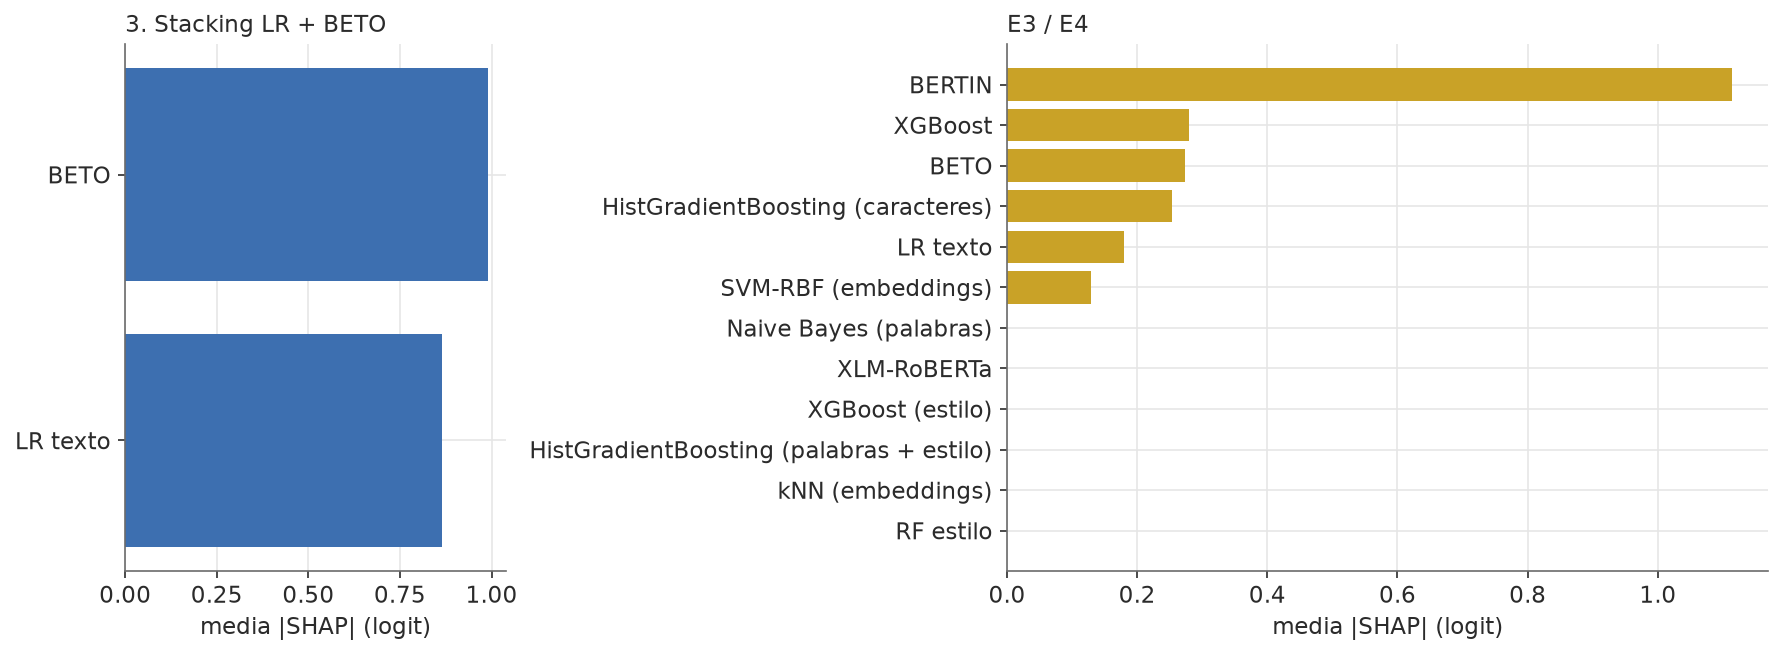

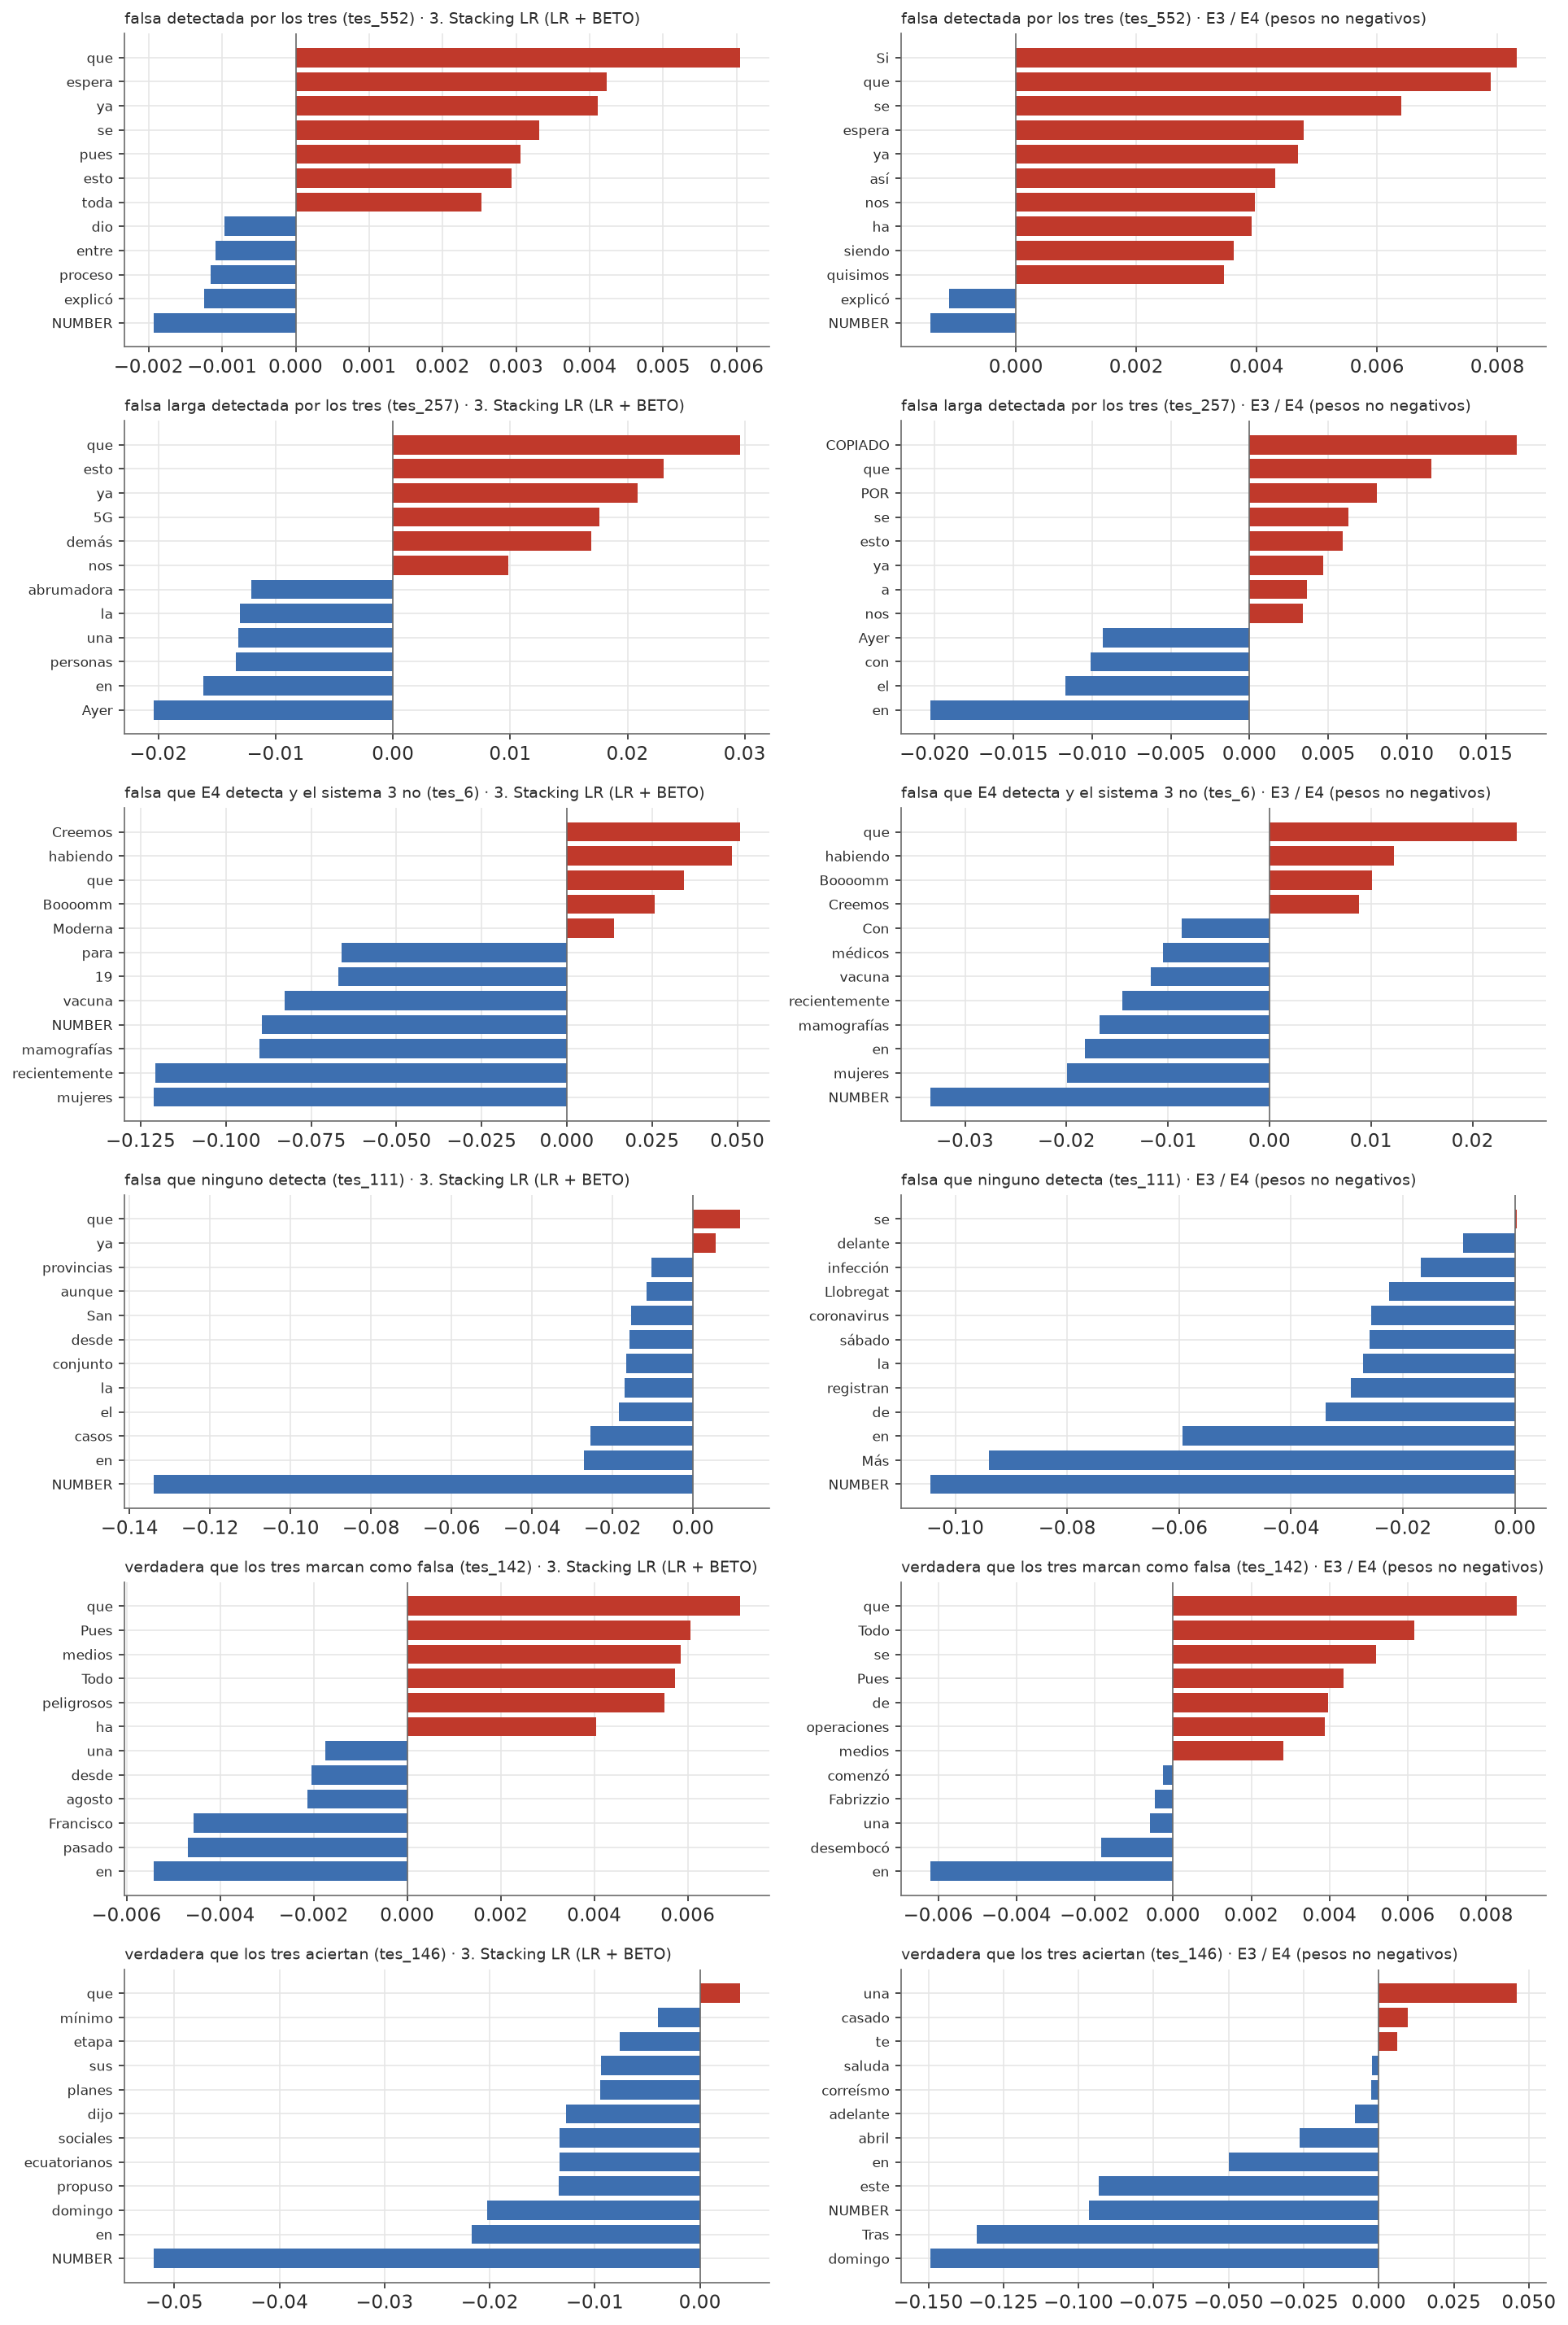

In [29]:
figura('7_1_finalistas_shap_bases', ancho = 860)
figura('8_2_finalistas_lime', ancho = 900)

**Tabla 10.4.** Noticias explicadas con LIME: probabilidad de cada finalista y R² local de LIME.

In [30]:
resumen_lime_f = leer('finalistas_lime_resumen.csv')
resumen_lime_f.pivot_table(index = ['caso', 'id_unico'], columns = 'sistema', values = ['prob de fake (texto completo)', 'R² local de LIME']).round(3)

R² local de LIME  \
sistema                                           3. Stacking LR (LR + BETO)   
caso                                     id_unico                              
falsa detectada por los tres             tes_552                       0.316   
falsa larga detectada por los tres       tes_257                       0.284   
falsa que E4 detecta y el sistema 3 no   tes_6                         0.656   
falsa que ninguno detecta                tes_111                       0.822   
verdadera que los tres aciertan          tes_146                       0.550   
verdadera que los tres marcan como falsa tes_142                       0.285   

                                                                                \
sistema                                           E3 / E4 (pesos no negativos)   
caso                                     id_unico                                
falsa detectada por los tres             tes_552                         0.606   
falsa larga detectada por los tres       tes_257                         0.457   
falsa que E4 detecta y el sistema 3 no   tes_6                           0.704   
falsa que ninguno detecta                tes_111                         0.803   
verdadera que los tres aciertan          tes_146                         0.772   
verdadera que los tres marcan como falsa tes_142                         0.427   

                                                  prob de fake (texto completo)  \
sistema                                              3. Stacking LR (LR + BETO)   
caso                                     id_unico                                 
falsa detectada por los tres             tes_552                          0.979   
falsa larga detectada por los tres       tes_257                          0.906   
falsa que E4 detecta y el sistema 3 no   tes_6                            0.474   
falsa que ninguno detecta                tes_111                          0.084   
verdadera que los tres aciertan          tes_146                          0.065   
verdadera que los tres marcan como falsa tes_142                          0.962   

                                                                                
sistema                                           E3 / E4 (pesos no negativos)  
caso                                     id_unico                               
falsa detectada por los tres             tes_552                         0.977  
falsa larga detectada por los tres       tes_257                         0.899  
falsa que E4 detecta y el sistema 3 no   tes_6                           0.861  
falsa que ninguno detecta                tes_111                         0.063  
verdadera que los tres aciertan          tes_146                         0.057  
verdadera que los tres marcan como falsa tes_142                         0.962

**Qué se observa.**

* **En CV, E3 y E4 aventajan al sistema 3:** 0.8116 ± 0.057 y 0.813 ± 0.0596, contra 0.7463 ± 0.0554 (Tabla 10.1). La ventaja viene sobre todo del fold de la sátira, donde BERTIN reconoce el estilo de *El Ruinaversal*.
* **En el test quedan juntos:** sistema 3 0.7357 [0.690, 0.778], E3 0.7496 [0.708, 0.789] y E4 0.7550 [0.715, 0.794].
  * Ninguna diferencia entre ellos es significativa (Tabla 10.2): E4 − sistema 3 = +0.019, IC [−0.019, +0.056].
  * Los tres superan al principal (+0.059 a +0.079, IC sin el 0) y empatan con el umbral 0.34.
* **Cada uno acomoda el balance de otra forma:** el sistema 3 es el más preciso (0.7804) y el de mayor exactitud (0.7500); E4 detecta más falsas (exhaustividad 0.7972) a cambio de más falsas alarmas (precisión 0.7170).
* **Entrenamiento (Figura 10.2):** las pérdidas de BETO y BERTIN bajan sin problemas en las 4 épocas, los meta-modelos convergen en pocas iteraciones y el umbral de E4 está justo en el máximo de su curva.
* **Qué aporta cada base (Tabla 10.3):** en el sistema 3, BETO y la LR se reparten la decisión (53.4 % y 46.6 %). En E3 y E4, BERTIN aporta la mitad (50.0 %).
* **Qué palabras deciden (Figura 10.3 y Tabla 10.4):** los tres deciden sobre todo por el registro: el tono coloquial empuja hacia *Fake* y la crónica con cifras hacia *True*. Por eso los tres fallan igual cuando una falsa imita la crónica o una verdadera es coloquial. El R² local de LIME va de 0.284 a 0.822: en noticias largas, las palabras sueltas explican poco de lo que leen los transformers.

**Los tres finalistas son igual de buenos en el test. El sistema 3 es el que se puede defender con el protocolo y el más simple; E4 es el que más falsas detecta, con la advertencia de que se diseñó después de ver el test y depende de BERTIN.**

<a id="conclusiones"></a>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

<a id="seccion-11"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 11: Todos los sistemas en una tabla</span></div>

> **Qué se hace:** juntamos en una sola tabla todos los sistemas evaluados en el test durante el proyecto, con su CV, su test, su IC95 y en qué momento se diseñaron.
>
> **Qué se espera ver:** una vista completa: qué funcionó, qué no y qué tanto se puede creer cada número.

In [31]:
def tipo_de(nombre, bloque_beto):
    '''
    Función que clasifica un sistema según cuándo se diseñó respecto al test

    inputs:
    --------
        nombre (str): Nombre del sistema
        bloque_beto (str): Bloque en beto_resumen_sistemas.csv ('' si no viene de ahí)

    outputs:
    --------
        str: 'principal', 'fijado antes del test', 'sistema aparte' o 'exploratorio'
    '''
    if nombre == 'LR texto (principal)':
        return 'principal'
    if bloque_beto == 'exploratorio':
        return 'exploratorio'
    if bloque_beto == '':
        return 'fijado antes del test'
    return 'sistema aparte'

filas = []
for _, fila in test_final.iterrows():
    filas.append({'sistema': fila['sistema'], 'tipo': tipo_de(fila['sistema'], ''), 'notebook': 'evaluacion',
                  'F1 fake CV': fila['F1_fake en CV'], 'F1 fake test': fila['F1_fake'], 'IC95 test': fila['IC95 F1_fake']})
umbral_test = leer('umbral_test.csv')
fila = umbral_test.iloc[1]
filas.append({'sistema': 'LR texto, umbral 0.34', 'tipo': 'sistema aparte', 'notebook': 'umbral',
              'F1 fake CV': fila['F1_fake en CV (anidada)'], 'F1 fake test': fila['F1_fake'], 'IC95 test': fila['IC95 F1_fake']})
stacking_test = leer('stacking_test.csv')
for nombre in ['XGBoost', 'Soft voting (3 bases)', 'Stacking (meta-modelo LR)']:
    fila = stacking_test[stacking_test['sistema'] == nombre].iloc[0]
    filas.append({'sistema': f'{nombre} [sin BETO]', 'tipo': 'sistema aparte', 'notebook': 'ensamble_stacking',
                  'F1 fake CV': fila['F1_fake en CV'], 'F1 fake test': fila['F1_fake'], 'IC95 test': fila['IC95 F1_fake']})
repetidos = ['LR texto (principal)', 'XGBoost', 'RF estilo', 'LR texto, umbral 0.34 (referencia)', 'Stacking viejo reportado (referencia)']
for _, fila in resumen_beto.iterrows():
    if fila['sistema'] in repetidos:
        continue
    filas.append({'sistema': fila['sistema'], 'tipo': tipo_de(fila['sistema'], fila['bloque'] if fila['exploratorio'] == 'no' else 'exploratorio'),
                  'notebook': 'ensamble_beto', 'F1 fake CV': fila['CV F1_fake'], 'F1 fake test': fila['test F1_fake'], 'IC95 test': fila['test IC95 F1_fake']})
todos = pd.DataFrame(filas)
todos['test − CV'] = todos['F1 fake test'] - todos['F1 fake CV']
todos['¿supera .7217 (BoW oficial)?'] = np.where(todos['F1 fake test'] > OFICIALES['Baseline BoW + SVM'], 'sí (puntual)', 'no')
print(f'{len(todos)} sistemas evaluados en el test; {int((todos["tipo"] == "exploratorio").sum())} exploratorios')

30 sistemas evaluados en el test; 11 exploratorios


**Tabla 11.1.** Todos los sistemas evaluados en el test, ordenados por F1 de fake en el test. "Sí (puntual)" quiere decir que la estimación supera al baseline oficial, pero su IC95 lo incluye.

In [32]:
todos.sort_values('F1 fake test', ascending = False).reset_index(drop = True).round(4)

,sistema,tipo,notebook,F1 fake CV,F1 fake test,IC95 test,test − CV,¿supera .7217 (BoW oficial)?
0,6. Stacking LR (4 bases + longitud),sistema aparte,ensamble_beto,0.7078,0.7566,"[0.712, 0.796]",0.0488,sí (puntual)
1,FT-Transformer (exploratorio),exploratorio,ensamble_beto,0.7144,0.7551,"[0.713, 0.795]",0.0407,sí (puntual)
2,E4. Stacking no negativo + umbral anidado (exp...,exploratorio,ensamble_beto,0.8130,0.7550,"[0.715, 0.794]",-0.0580,sí (puntual)
3,"E3. Stacking no negativo, todas las bases (exp...",exploratorio,ensamble_beto,0.8116,0.7496,"[0.708, 0.789]",-0.0620,sí (puntual)
4,5. Stacking MLP (4 bases),sistema aparte,ensamble_beto,0.7343,0.7450,"[0.700, 0.783]",0.0107,sí (puntual)
5,E1. Sistema 3 + umbral anidado (exploratorio),exploratorio,ensamble_beto,0.7472,0.7440,"[0.702, 0.781]",-0.0032,sí (puntual)
6,E2. Stacking LR (LR + 3 transformers) (explora...,exploratorio,ensamble_beto,0.7984,0.7397,"[0.696, 0.779]",-0.0587,sí (puntual)
7,4. Stacking LR (4 bases),sistema aparte,ensamble_beto,0.7299,0.7378,"[0.693, 0.778]",0.0079,sí (puntual)
8,7. Stacking MLP (4 bases + longitud),sistema aparte,ensamble_beto,0.7231,0.7364,"[0.692, 0.776]",0.0133,sí (puntual)
9,3. Stacking LR (LR + BETO),sistema aparte,ensamble_beto,0.7463,0.7357,"[0.690, 0.778]",-0.0106,sí (puntual)


**Figura 11.1.** F1 de fake en el test con IC95 de los sistemas clave del proyecto, por tipo; las líneas son los resultados oficiales.

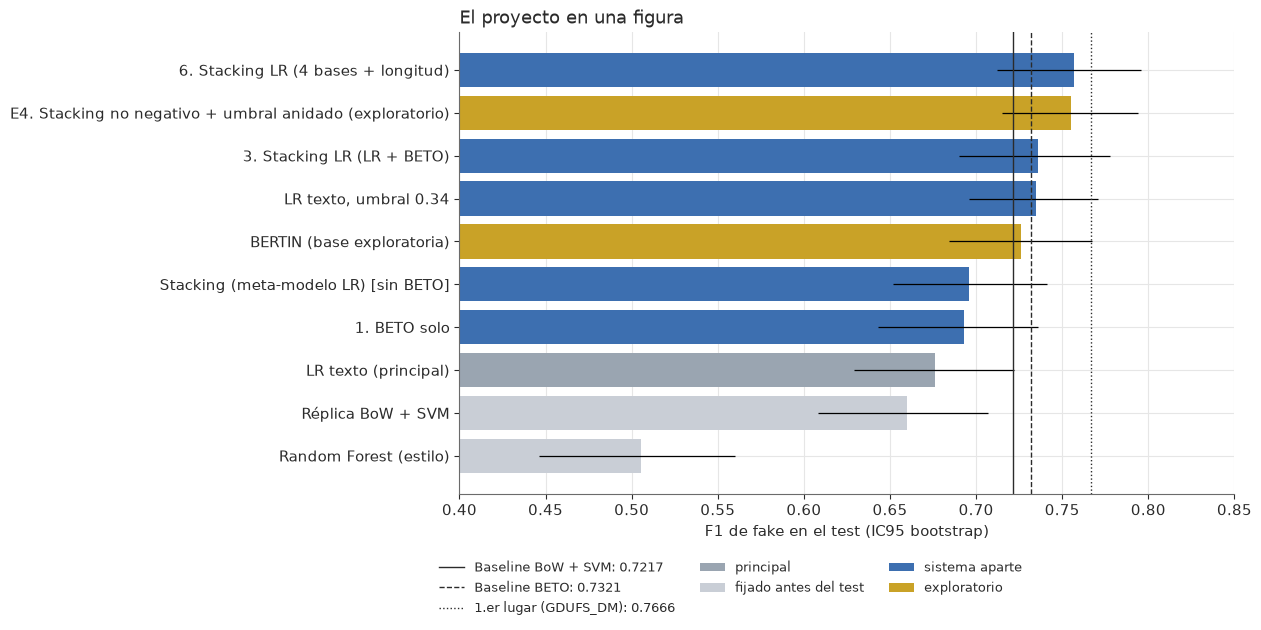

In [33]:
CLAVE = ['LR texto (principal)', 'Réplica BoW + SVM', 'Random Forest (estilo)', 'LR texto, umbral 0.34', 'Stacking (meta-modelo LR) [sin BETO]',
         '1. BETO solo', '3. Stacking LR (LR + BETO)', '6. Stacking LR (4 bases + longitud)', 'BERTIN (base exploratoria)',
         'E4. Stacking no negativo + umbral anidado (exploratorio)']
COLOR_TIPO = {'principal': '#9aa5b1', 'fijado antes del test': '#c9ced6', 'sistema aparte': '#3D6FB0', 'exploratorio': '#c9a227'}
clave = todos[todos['sistema'].isin(CLAVE)].sort_values('F1 fake test')
abajo = []
arriba = []
colores = []
for _, fila in clave.iterrows():
    limites = fila['IC95 test'].strip('[]').split(',')
    abajo.append(fila['F1 fake test'] - float(limites[0]))
    arriba.append(float(limites[1]) - fila['F1 fake test'])
    colores.append(COLOR_TIPO[fila['tipo']])
fig, ax = plt.subplots(figsize = (10, 6))
ax.barh(clave['sistema'], clave['F1 fake test'], xerr = np.array([abajo, arriba]), color = colores, error_kw = {'lw': 0.9})
manijas = []
for (etiqueta, valor), estilo in zip(OFICIALES.items(), ['-', '--', ':']):
    manijas.append(ax.axvline(valor, color = TINTA, linestyle = estilo, linewidth = 1, label = f'{etiqueta}: {valor:.4f}'))
for tipo, color in COLOR_TIPO.items():
    manijas.append(Patch(facecolor = color, label = tipo))
ax.set_xlim(0.4, 0.85)
ax.set_xlabel('F1 de fake en el test (IC95 bootstrap)')
ax.set_title('El proyecto en una figura')
ax.legend(handles = manijas, loc = 'upper center', bbox_to_anchor = (0.35, -0.12), ncol = 3, fontsize = 9)
guardar(fig, '11_1_resumen_f1_test')
plt.show()

**Qué se observa.**

* **Se evaluaron 30 sistemas en el test** a lo largo del proyecto, 11 de ellos exploratorios (Tabla 10.1).
* **13 superan al baseline oficial de BoW (.7217) en estimación puntual**, pero ninguno con un IC95 que lo excluya. Ninguno es de los sistemas fijados antes de la primera evaluación: todos son sistemas aparte o exploratorios.
* **El más alto en el test es el sistema 6** (0.7566, IC95 [0.712, 0.796]), seguido del FT-Transformer exploratorio (0.7551) y de E4 (0.7550). Ninguno de ellos era el mejor en CV.
* **La columna "test − CV" separa dos grupos.**
  * Los sistemas de la primera evaluación pierden entre 0.047 y 0.103 al pasar al test (el principal, −0.0536), por el cambio de época y de temas.
  * Los que usan BERTIN pierden alrededor de 0.06 (BERTIN solo, −0.0841): su CV era optimista.
  * Los stackings con BETO y el umbral 0.34 cambian poco (de −0.0106 a +0.0133), salvo el sistema 6, que sube +0.0488.

**El proyecto pasó de 0.676 (principal) a ≈ 0.74–0.76 en el test con sistemas aparte, en el rango de los baselines oficiales, pero sin diferencias significativas entre los mejores.**

<a id="seccion-12"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 12: Línea de decisiones</span></div>

> **Qué se hace:** enumeramos las decisiones que más cambiaron el proyecto, cuándo se tomaron y con qué información.
>
> **Qué se espera ver:** que ninguna decisión del sistema principal se haya tomado viendo el test, y que lo posterior esté marcado como tal.

**Tabla 12.1.** Decisiones del proyecto. "Antes del test" se refiere a la primera evaluación en el test (`evaluacion.ipynb`, 22 de noviembre).

| Fecha | Decisión | Alternativa descartada | Con qué se decidió | ¿Antes del test? |
|:--|:--|:--|:--|:--|
| 22-nov | F1 de *fake* como métrica principal | macro-F1 | Reglas del concurso | ✅ |
| 22-nov | Solo titular y texto; nada de fuente, tema ni enlace | Usar metadatos como el 2.º lugar | V de Cramér fuente–clase 0.996 | ✅ |
| 22-nov | Folds agrupados por fuente para **toda** la validación | Validar con `development` o folds aleatorios | Los folds aleatorios inflan 0.09–0.11 | ✅ |
| 22-nov | Borrar los nombres de medio del texto | Marcarlos con `<MEDIO>` | Cuesta ≤ 0.003 y quita el atajo | ✅ |
| 22-nov | Eliminar 4 casi duplicados de noticias del test | Conservarlos | Fuga directa hacia el test | ✅ |
| 22-nov | Usar solo el texto, sin el titular | Concatenar o en bloques | El titular empeoró la CV | ✅ |
| 22-nov | Regla de selección revisada (LR palabras + caracteres) | SVM + χ² (regla original) | La regla original quedaba debajo de la réplica BoW en CV | ✅ (después de la CV) |
| 22-nov | Evaluar en el test una sola vez | — | Protocolo | — |
| 26-nov | Umbral 0.34 como sistema aparte | Dejar 0.5 | CV anidada; motivado por la baja exhaustividad del test | ❌ |
| 26-nov | Ensamble LR + XGBoost + RF | — | CV anidada: no ayuda | ❌ |
| 26-nov | Agregar BETO y fijar 7 sistemas antes de verlos | — | Tarea del equipo | ❌ (fijados antes de su propio test) |
| 26-nov | Aceptar el fold de la sátira (BETO inestable) | Cambiar la configuración de BETO | Diagnóstico: *El Ruinaversal* | ❌ |
| 26-nov | Usar XGBoost de Linux (0.6855) | Correr en Windows | Diferencia entre sistemas operativos | ❌ |
| 27-nov | Exploraciones (boostings, SVM, kNN, NB, BERTIN, XLM-R, meta-modelos) | — | Propuestas del equipo después de ver el test | ❌ exploratorio |
| 27-nov | BERTIN y XLM-RoBERTa en lugar de MarIA | MarIA | MarIA ya no tenía pesos públicos | ❌ exploratorio |
| 27-nov | Prueba de contaminación y auditoría de fuga | — | La CV de BERTIN parecía demasiado buena | ❌ |
| 27-nov | Tres finalistas: sistema 3 (elegido por el protocolo), E3 y E4 (mejores en CV) | Un solo sistema final | Decisión del equipo; E3 y E4 con advertencia | ❌ |

<a id="seccion-13"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 13: Respuestas, limitaciones y lo que falta</span></div>

> **Qué se hace:** respondemos las preguntas del proyecto con las cifras de este notebook.
>
> **Qué se espera ver:** una respuesta honesta: qué se logró, qué no, y qué tanto confiar en cada resultado.

**¿Se cumplió el objetivo?** **En parte.**

* El sistema principal, elegido y evaluado con todo el rigor del protocolo, **no** supera al baseline oficial de BoW + SVM: 0.6764 contra .7217.
* Los sistemas aparte sí lo superan en estimación puntual: el umbral 0.34 (0.7346) y el stacking LR + BETO (0.7357). También quedan arriba del baseline oficial de BETO (.7321). Pero sus intervalos incluyen a los dos baselines: **no está demostrado**.
* **Los tres finalistas** (Sección 10):
  * el **stacking LR + BETO (sistema 3)**, el elegido por el protocolo: 0.7357 en el test, el más preciso y el más simple;
  * **E3** (pesos no negativos sobre 12 bases): 0.7496;
  * **E4** (E3 con umbral anidado): 0.7550, el que más falsas detecta.

  En el test no se distinguen entre sí ni del umbral 0.34. Se recomienda reportar el **sistema 3 como sistema final** y **E4 como el mejor resultado exploratorio**, con su advertencia: se diseñó después de ver el test y su CV se apoya en BERTIN.

**Lo que aprendimos (y vale tanto como el número):**

1. **La fuente es un atajo** y los folds aleatorios inflan la F1 entre 0.09 y 0.11. Validar agrupando por fuente es lo que hace creíbles los números.
2. **El modelo principal es preciso pero tímido:** su punto débil son las falsas largas, escritas como nota de prensa. Bajar el umbral y agregar BETO las rescatan en parte.
3. **Un ensamble solo ayuda si sus bases se equivocan distinto.** Árboles y boostings sobre las mismas palabras no ayudaron; BETO sí.
4. **Un modelo preentrenado puede conocer de antemano el estilo de los medios del corpus** (BERTIN). Eso infla la validación aunque no haya fuga de etiquetas.

**Limitaciones:**

* El test se usó más de una vez. La primera evaluación (Sección 6) fue única; todo lo posterior es sistema aparte o exploratorio, y así se reporta.
* No se replicó el preprocesamiento oficial (lematización), que explica parte de la brecha con los baselines.
* La CV de los meta-modelos usa el esquema B, que es optimista. Los transformers no tienen *grid search* y son inestables en el fold de la sátira.
* No hay acuerdo entre anotadores publicado: no se puede saber cuánto ruido tienen las etiquetas.

**Lo que falta para la entrega:** la API de demostración (publicarla requiere crear una cuenta; se decide en equipo) y el reporte final, que puede seguir este mismo orden.

<a id="seccion-14"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 14: Cómo reproducir todo</span></div>

> **Qué se hace:** listamos el orden de ejecución, el tiempo de cada paso y lo que necesita cada uno.
>
> **Qué se espera ver:** que cualquiera del equipo pueda regenerar todos los resultados.

| # | Paso | Qué hace | Tiempo aprox. | Necesita |
|:--|:--|:--|:--|:--|
| 1 | `analisis_exploratorio.ipynb` | EDA y calidad de datos | minutos | entorno `fakedes` |
| 2 | `preparacion_datos.ipynb` | Limpieza, rasgos y folds; crea `data/processed/` | ≈ 1 min | — |
| 3 | `modelos_lineales.ipynb` | CV de lineales y baselines | ≈ 18 min (4 núcleos) | — |
| 4 | `modelo_arboles.ipynb` | Random Forest de estilo | ≈ 5 min | — |
| 5 | `evaluacion.ipynb` | Única evaluación en el test de los sistemas fijados; guarda el modelo | minutos | — |
| 6 | `umbral.ipynb` | Umbral de decisión (sistema aparte) | ≈ 1.5 min | — |
| 7 | `ensamble_stacking.ipynb` | XGBoost y primer stacking | ≈ 5 min | `xgboost` |
| 8 | `beto_entrenar.py` | BETO (y con `--modelo`, BERTIN y XLM-RoBERTa) | ≈ 70 min por modelo | GPU con CUDA; `requirements_beto.txt` |
| 9 | `beto_embeddings.py`, `contaminacion_mlm.py`, `contaminacion_busqueda.py` | *Embeddings* y pruebas de contaminación | minutos | GPU; internet para la búsqueda |
| 10 | `beto_resultados.ipynb` | Verifica las salidas de BETO | segundos | — |
| 11 | `ensamble_beto.ipynb` | Stacking con BETO y exploraciones | ≈ 75 min | `torch` (CPU basta) |
| 12 | `finalistas_lime.py` | LIME de los tres finalistas (reentrena las bases con las 961 noticias) | ≈ 45 min | GPU |
| 13 | `finalistas.ipynb` | Análisis a fondo de los tres finalistas | ≈ 1 min | — |
| 14 | `resumen_proyecto.ipynb` | Este notebook | segundos | solo `resultados/` y `figuras/` |

Cada notebook se ejecuta con `jupyter nbconvert --to notebook --execute <notebook> --inplace` y el kernel `Python (fakedes)`. La tabla de reproducibilidad con hiperparámetros, resultados por fold y faltantes está en `resultados/reproducibilidad.xlsx`.

<a id="seccion-15"></a>

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Sección 15: Referencias</span></div>

> **Qué se hace:** fuentes principales.
>
> **Qué se espera ver:** referencias completas; cada notebook tiene las suyas.

1. Gómez-Adorno, H., Posadas-Durán, J. P., Bel Enguix, G. y Porto Capetillo, C. (2021). Overview of FakeDeS at IberLEF 2021: Fake News Detection in Spanish Shared Task. *Procesamiento del Lenguaje Natural*, 67, 223–231.
2. Huang, X., Xiong, J. y Jiang, S. (2021). GDUF_DM at FakeDeS 2021: Spanish Fake News Detection with BERT and Sample Memory. *CEUR-WS* Vol. 2943, 621–629.
3. Chapman, P. et al. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS.
4. Alegre Ventura, R. J. (2026). *Métodos de ensamble: bagging, boosting y stacking*. Materiales de Minería de Datos, LCD, IIMAS, UNAM.
5. Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H. y Pérez, J. (2020). Spanish Pre-Trained BERT Model and Evaluation Data. En *PML4DC at ICLR 2020* (BETO).
6. De la Rosa, J. et al. (2022). BERTIN: Efficient Pre-Training of a Spanish Language Model using Perplexity Sampling. *Procesamiento del Lenguaje Natural*, 68, 13–23.
7. Wolpert, D. H. (1992). Stacked generalization. *Neural Networks*, 5(2), 241–259.
8. Sun, C., Qiu, X., Xu, Y. y Huang, X. (2019). How to Fine-Tune BERT for Text Classification? En *CCL 2019*.
9. Ribeiro, M. T., Singh, S. y Guestrin, C. (2016). "Why Should I Trust You?": Explaining the Predictions of Any Classifier. En *KDD 2016* (LIME).
10. Lundberg, S. M. y Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. En *NeurIPS 2017* (SHAP).